In [1]:
# ============================================================
# Notebook 14
# Final Results & Visualization
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

plt.rcParams["figure.figsize"] = (12,6)
plt.rcParams["figure.dpi"] = 300

print("="*80)
print("NOTEBOOK 14")
print("Final Results & Visualization")
print("="*80)

NOTEBOOK 14
Final Results & Visualization


In [2]:
# ============================================================
# Cell 2
# Project Paths
# ============================================================

PROJECT_ROOT = Path(
    r"D:\Research\Papers\Paper_2"
)

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

TABLE_DIR = PROJECT_ROOT / "tables"

TABLE_DIR.mkdir(exist_ok=True)

FIGURE_DIR.mkdir(exist_ok=True)

print("="*80)
print("Directories")
print("="*80)

print(PROJECT_ROOT)
print(RESULT_DIR)
print(FIGURE_DIR)
print(TABLE_DIR)

Directories
D:\Research\Papers\Paper_2
D:\Research\Papers\Paper_2\results
D:\Research\Papers\Paper_2\figures
D:\Research\Papers\Paper_2\tables


In [3]:
from pathlib import Path
import pandas as pd

DRIVE = "2011_09_26_drive_0001_sync"

PROJECT_ROOT = Path(r"D:\Research\Papers\Paper_2")
RESULT_DIR = PROJECT_ROOT / "results"

def load_file(pattern):
    files = sorted(RESULT_DIR.glob(pattern))

    if len(files) == 0:
        raise FileNotFoundError(f"No file found for pattern: {pattern}")

    print(f"Loaded : {files[0].name}")
    return pd.read_csv(files[0])

quality = load_file(f"sensor_quality_metrics*{DRIVE}*.csv")
camera = load_file(f"dynamic_weight_generation*{DRIVE}*.csv")
sci = load_file(f"sensor_confidence_index*{DRIVE}*.csv")
weights = load_file(f"adaptive_sensor_weights*{DRIVE}*.csv")
fusion = load_file(f"confidence_driven_sensor_fusion*{DRIVE}*.csv")
ekf = load_file(f"adaptive_ekf_results*{DRIVE}*.csv")
ml = load_file("localization_error_prediction.csv")

print("\nAll datasets loaded successfully.\n")

print("Quality :", quality.shape)
print("Camera  :", camera.shape)
print("SCI     :", sci.shape)
print("Weights :", weights.shape)
print("Fusion  :", fusion.shape)
print("EKF     :", ekf.shape)
print("ML      :", ml.shape)

Loaded : sensor_quality_metrics_2011_09_26_drive_0001_sync.csv
Loaded : dynamic_weight_generation_2011_09_26_drive_0001_sync.csv
Loaded : sensor_confidence_index_2011_09_26_drive_0001_sync.csv
Loaded : adaptive_sensor_weights_2011_09_26_drive_0001_sync.csv
Loaded : confidence_driven_sensor_fusion_2011_09_26_drive_0001_sync.csv
Loaded : adaptive_ekf_results_2011_09_26_drive_0001_sync.csv
Loaded : localization_error_prediction.csv

All datasets loaded successfully.

Quality : (108, 40)
Camera  : (108, 18)
SCI     : (108, 43)
Weights : (108, 14)
Fusion  : (108, 21)
EKF     : (108, 18)
ML      : (22, 2)


In [4]:
# ============================================================
# Cell 4
# Dataset Summary
# ============================================================

summary = pd.DataFrame({

"Dataset":[
"Sensor Quality",
"Camera Confidence",
"SCI",
"Adaptive Weights",
"Fusion",
"Adaptive EKF",
"Machine Learning"
],

"Samples":[

len(quality),

len(camera),

len(sci),

len(weights),

len(fusion),

len(ekf),

len(ml)

]

})

display(summary)

summary.to_csv(

TABLE_DIR/

"dataset_summary.csv",

index=False

)

,Dataset,Samples
0,Sensor Quality,108
1,Camera Confidence,108
2,SCI,108
3,Adaptive Weights,108
4,Fusion,108
5,Adaptive EKF,108
6,Machine Learning,22


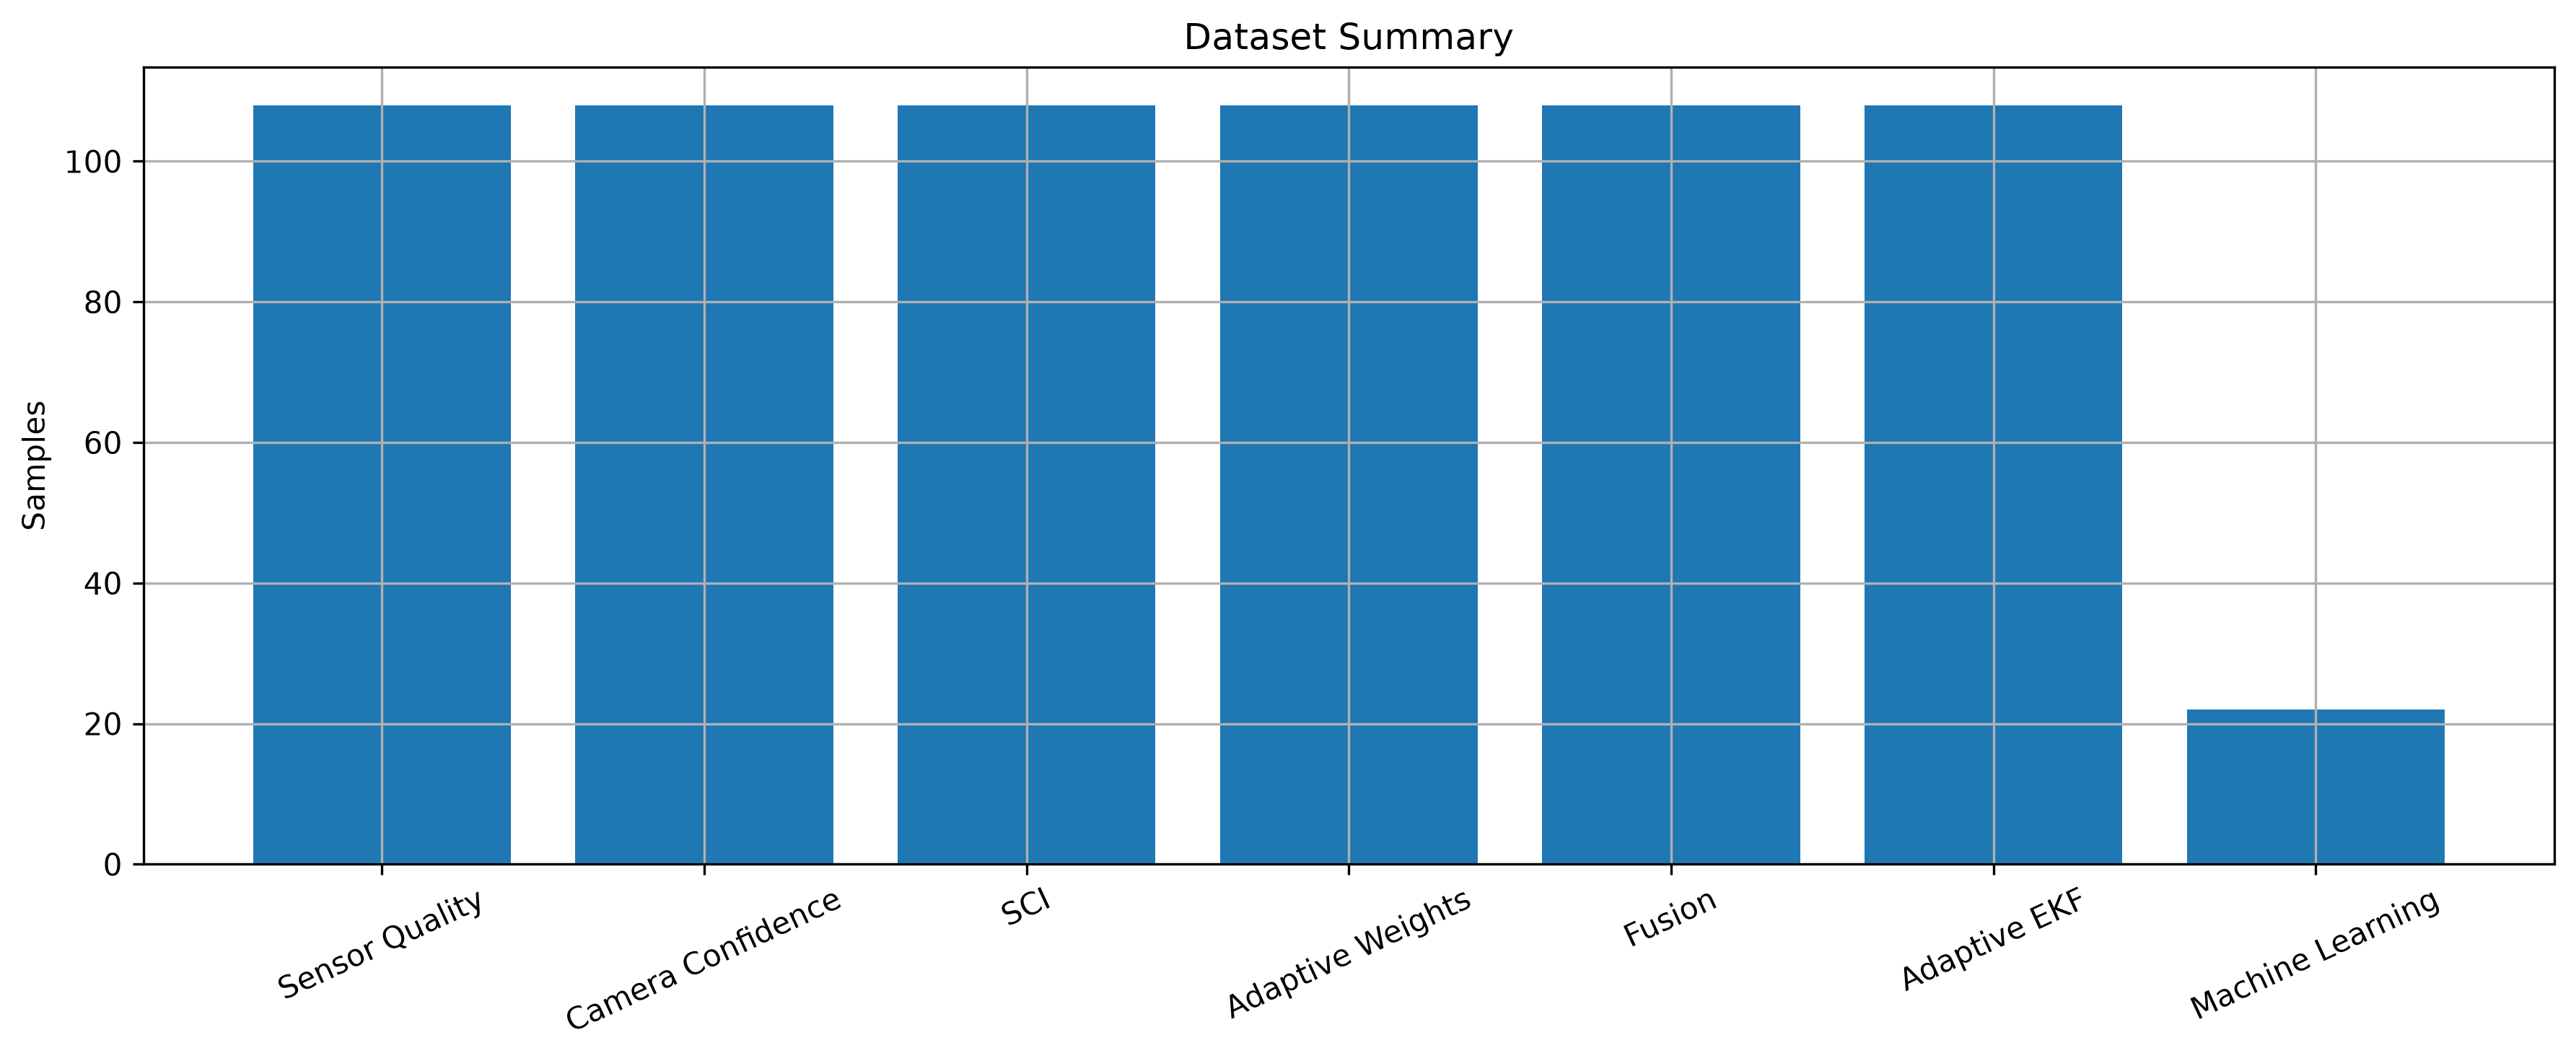

In [5]:
# ============================================================
# Cell 5
# Dataset Summary Figure
# ============================================================

plt.figure(figsize=(12,5))

plt.bar(

summary["Dataset"],

summary["Samples"]

)

plt.xticks(rotation=25)

plt.ylabel("Samples")

plt.title("Dataset Summary")

plt.grid(True)

plt.tight_layout()

plt.savefig(

FIGURE_DIR/

"Figure_01_Dataset_Summary.png",

dpi=300

)

plt.show()

In [6]:
# ============================================================
# Cell 6
# Dataset Statistics
# ============================================================

stats = pd.DataFrame({

"Metric":[

"Total Frames",

"Camera Frames",

"SCI Frames",

"Fusion Frames",

"EKF Frames",

"Prediction Samples"

],

"Value":[

len(quality),

len(camera),

len(sci),

len(fusion),

len(ekf),

len(ml)

]

})

display(stats)

stats.to_csv(

TABLE_DIR/

"dataset_statistics.csv",

index=False

)

,Metric,Value
0,Total Frames,108
1,Camera Frames,108
2,SCI Frames,108
3,Fusion Frames,108
4,EKF Frames,108
5,Prediction Samples,22


In [7]:
# ============================================================
# Cell 7
# Pipeline Summary
# ============================================================

print("="*80)

print("PIPELINE SUMMARY")

print("="*80)

print("""

Dataset Validation              ✓

Sensor Quality                  ✓

Camera Confidence               ✓

Sensor Confidence Index         ✓

Adaptive Weights                ✓

Confidence Fusion               ✓

Adaptive EKF                    ✓

Random Forest                   ✓

Performance Evaluation          ✓

Visualization                   ✓

""")

print("="*80)

PIPELINE SUMMARY


Dataset Validation              ✓

Sensor Quality                  ✓

Camera Confidence               ✓

Sensor Confidence Index         ✓

Adaptive Weights                ✓

Confidence Fusion               ✓

Adaptive EKF                    ✓

Random Forest                   ✓

Performance Evaluation          ✓

Visualization                   ✓




,Camera Confidence,Rolling Confidence,Smoothed Confidence
count,108.000000,108.000000,108.000000
mean,0.490494,0.487208,0.483995
std,0.148791,0.143208,0.138442
min,0.265978,0.288022,0.303642
25%,0.372924,0.372909,0.371520
50%,0.462247,0.455004,0.446591
75%,0.599867,0.605418,0.609943
max,0.816628,0.790853,0.771161


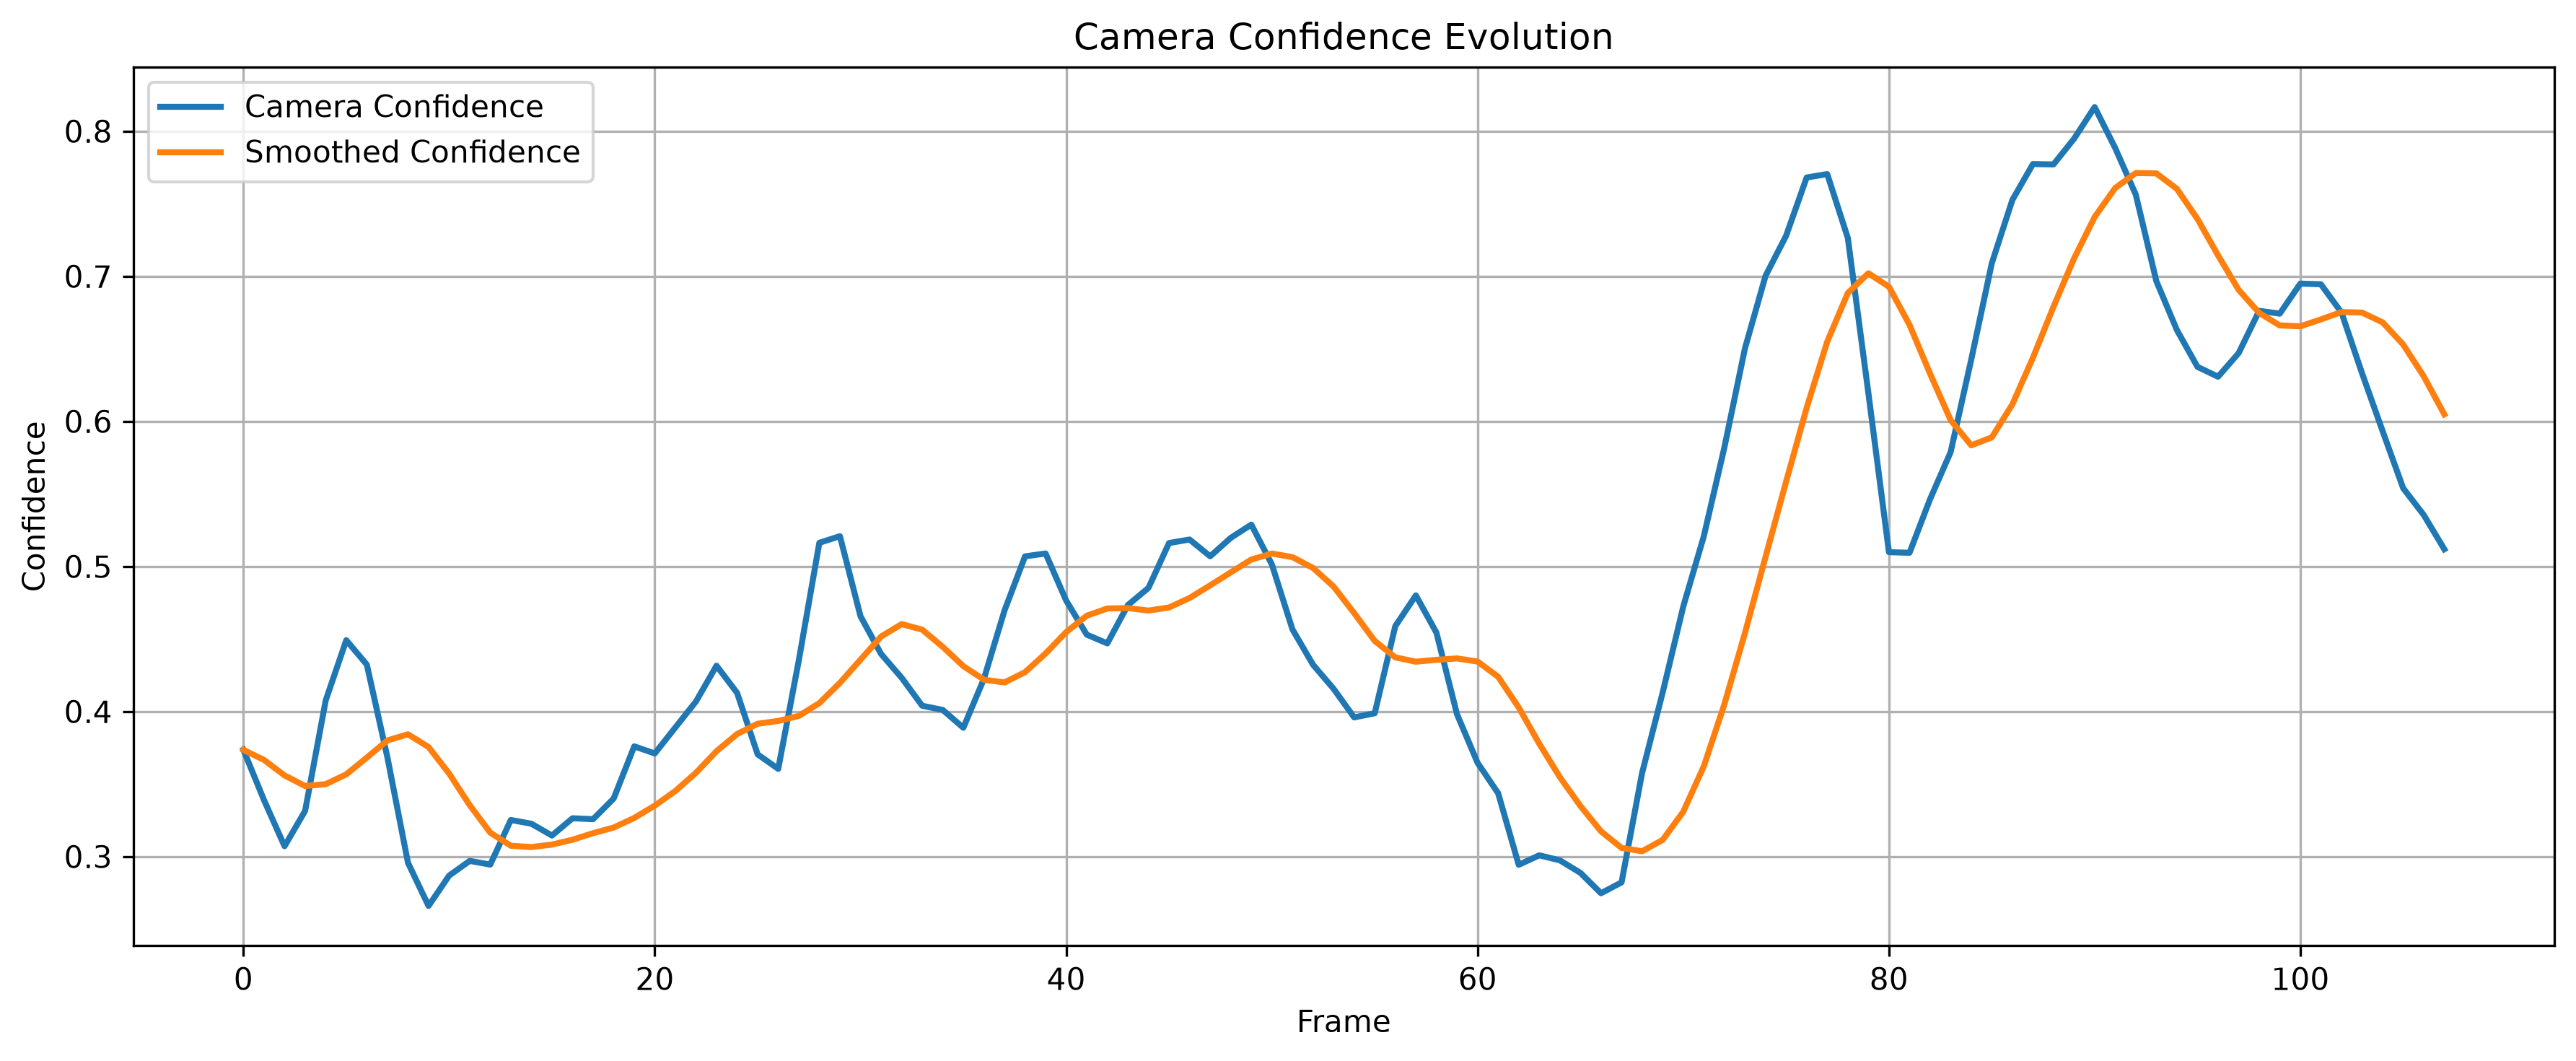

In [8]:
# ============================================================
# Cell 8
# Camera Confidence Analysis
# ============================================================

camera_stats = camera[[
    "Camera Confidence",
    "Rolling Confidence",
    "Smoothed Confidence"
]].describe()

display(camera_stats)

camera_stats.to_csv(
    TABLE_DIR /
    "camera_confidence_statistics.csv"
)

plt.figure(figsize=(12,5))

plt.plot(
    camera["Frame"],
    camera["Camera Confidence"],
    linewidth=2,
    label="Camera Confidence"
)

plt.plot(
    camera["Frame"],
    camera["Smoothed Confidence"],
    linewidth=2,
    label="Smoothed Confidence"
)

plt.grid(True)

plt.xlabel("Frame")

plt.ylabel("Confidence")

plt.title("Camera Confidence Evolution")

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure_02_Camera_Confidence.png",
    dpi=300
)

plt.show()

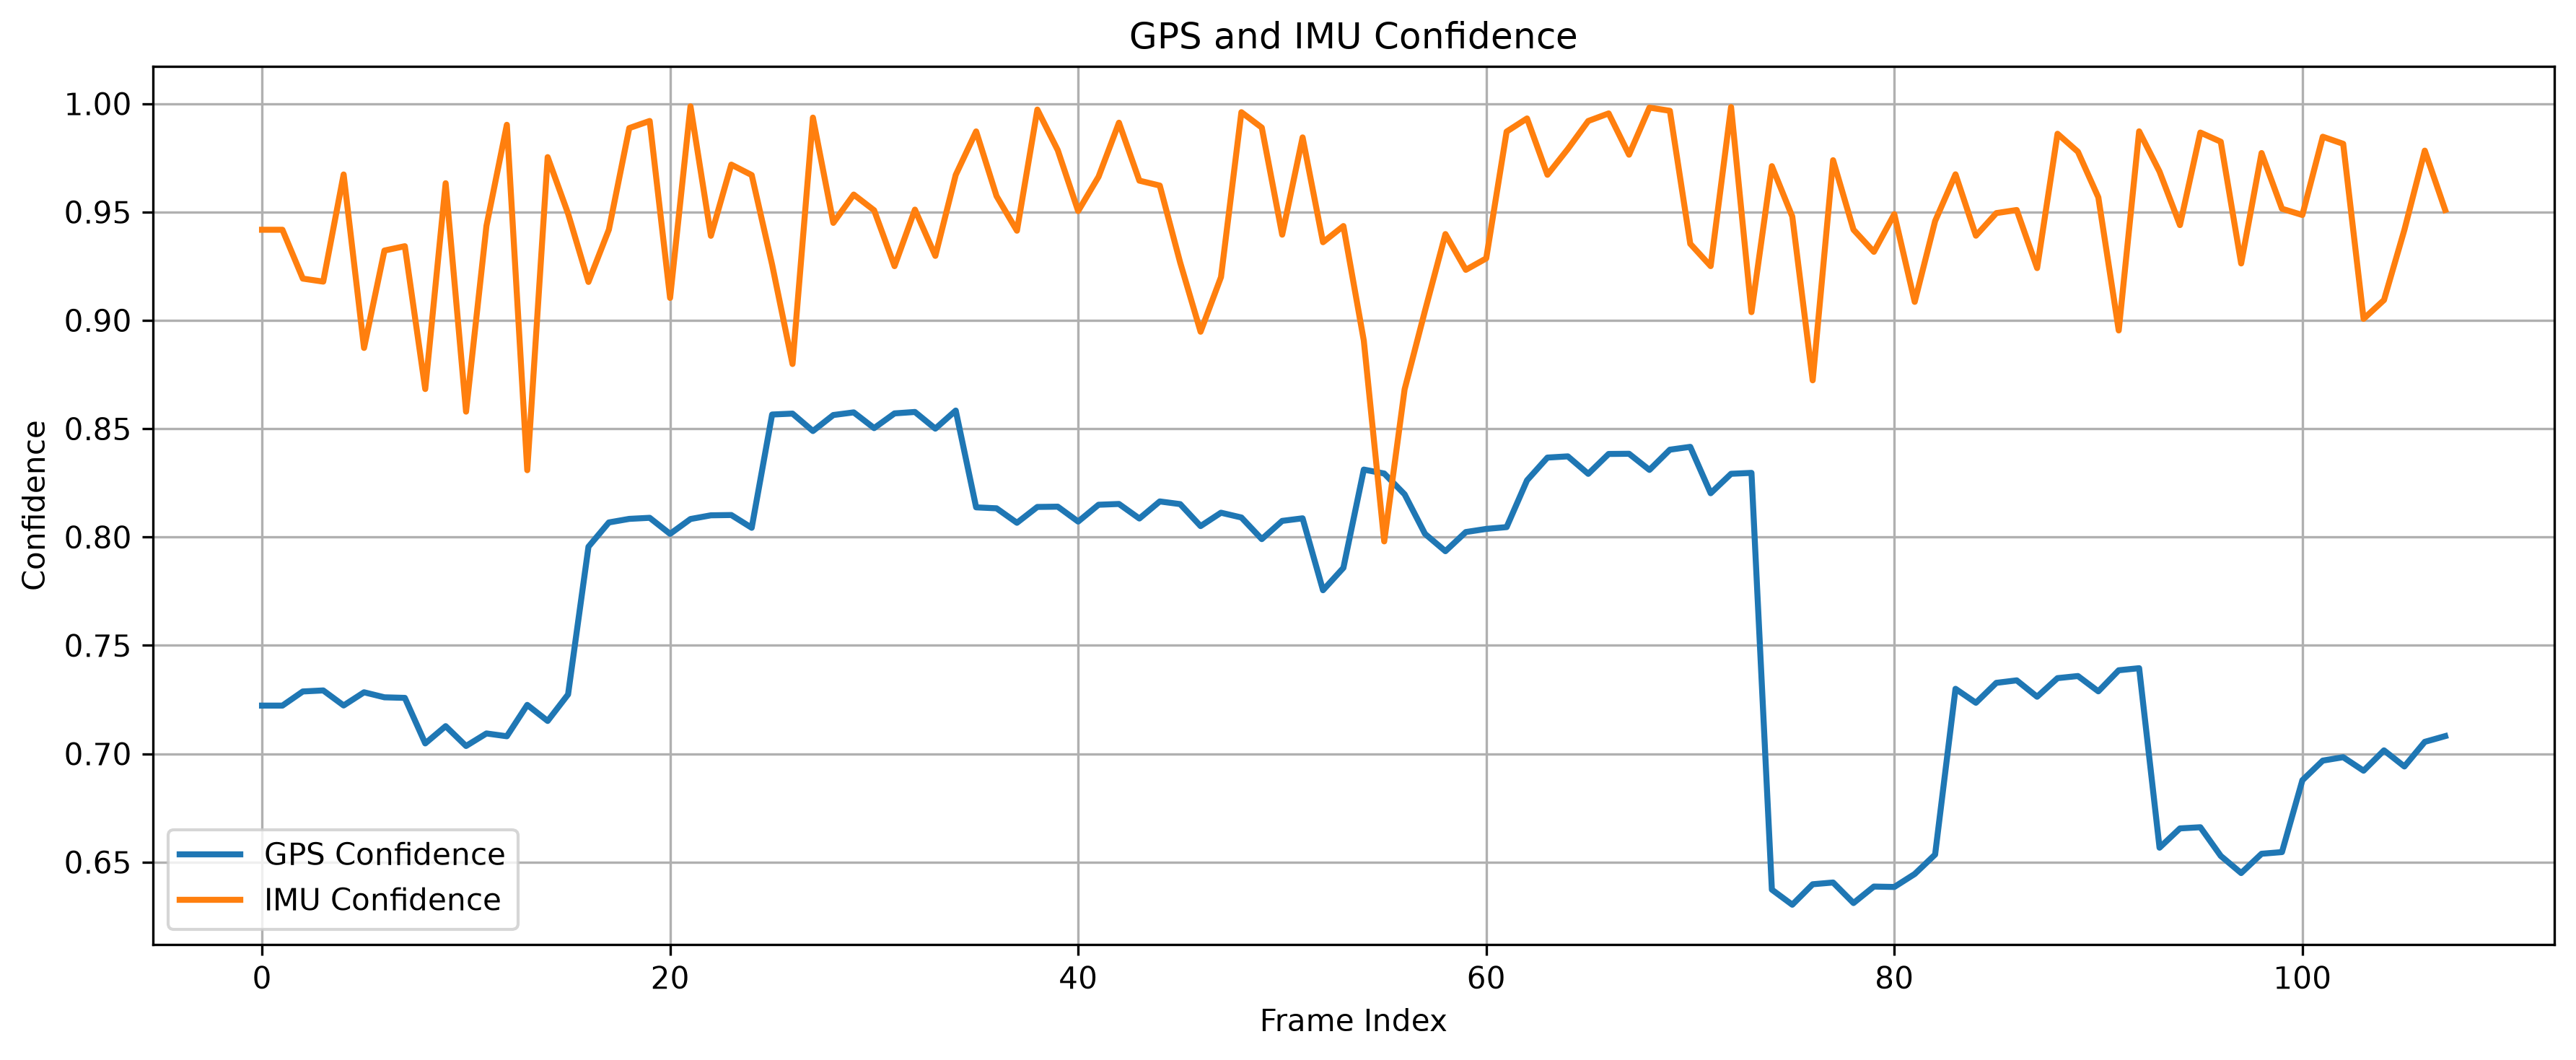

In [9]:
# ============================================================
# Cell 9
# GPS and IMU Confidence
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(
    sci.index,
    sci["GPS Confidence"],
    linewidth=2,
    label="GPS Confidence"
)

plt.plot(
    sci.index,
    sci["IMU Confidence"],
    linewidth=2,
    label="IMU Confidence"
)

plt.xlabel("Frame Index")
plt.ylabel("Confidence")
plt.title("GPS and IMU Confidence")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Figure_03_GPS_IMU_Confidence.png",
    dpi=300
)

plt.show()

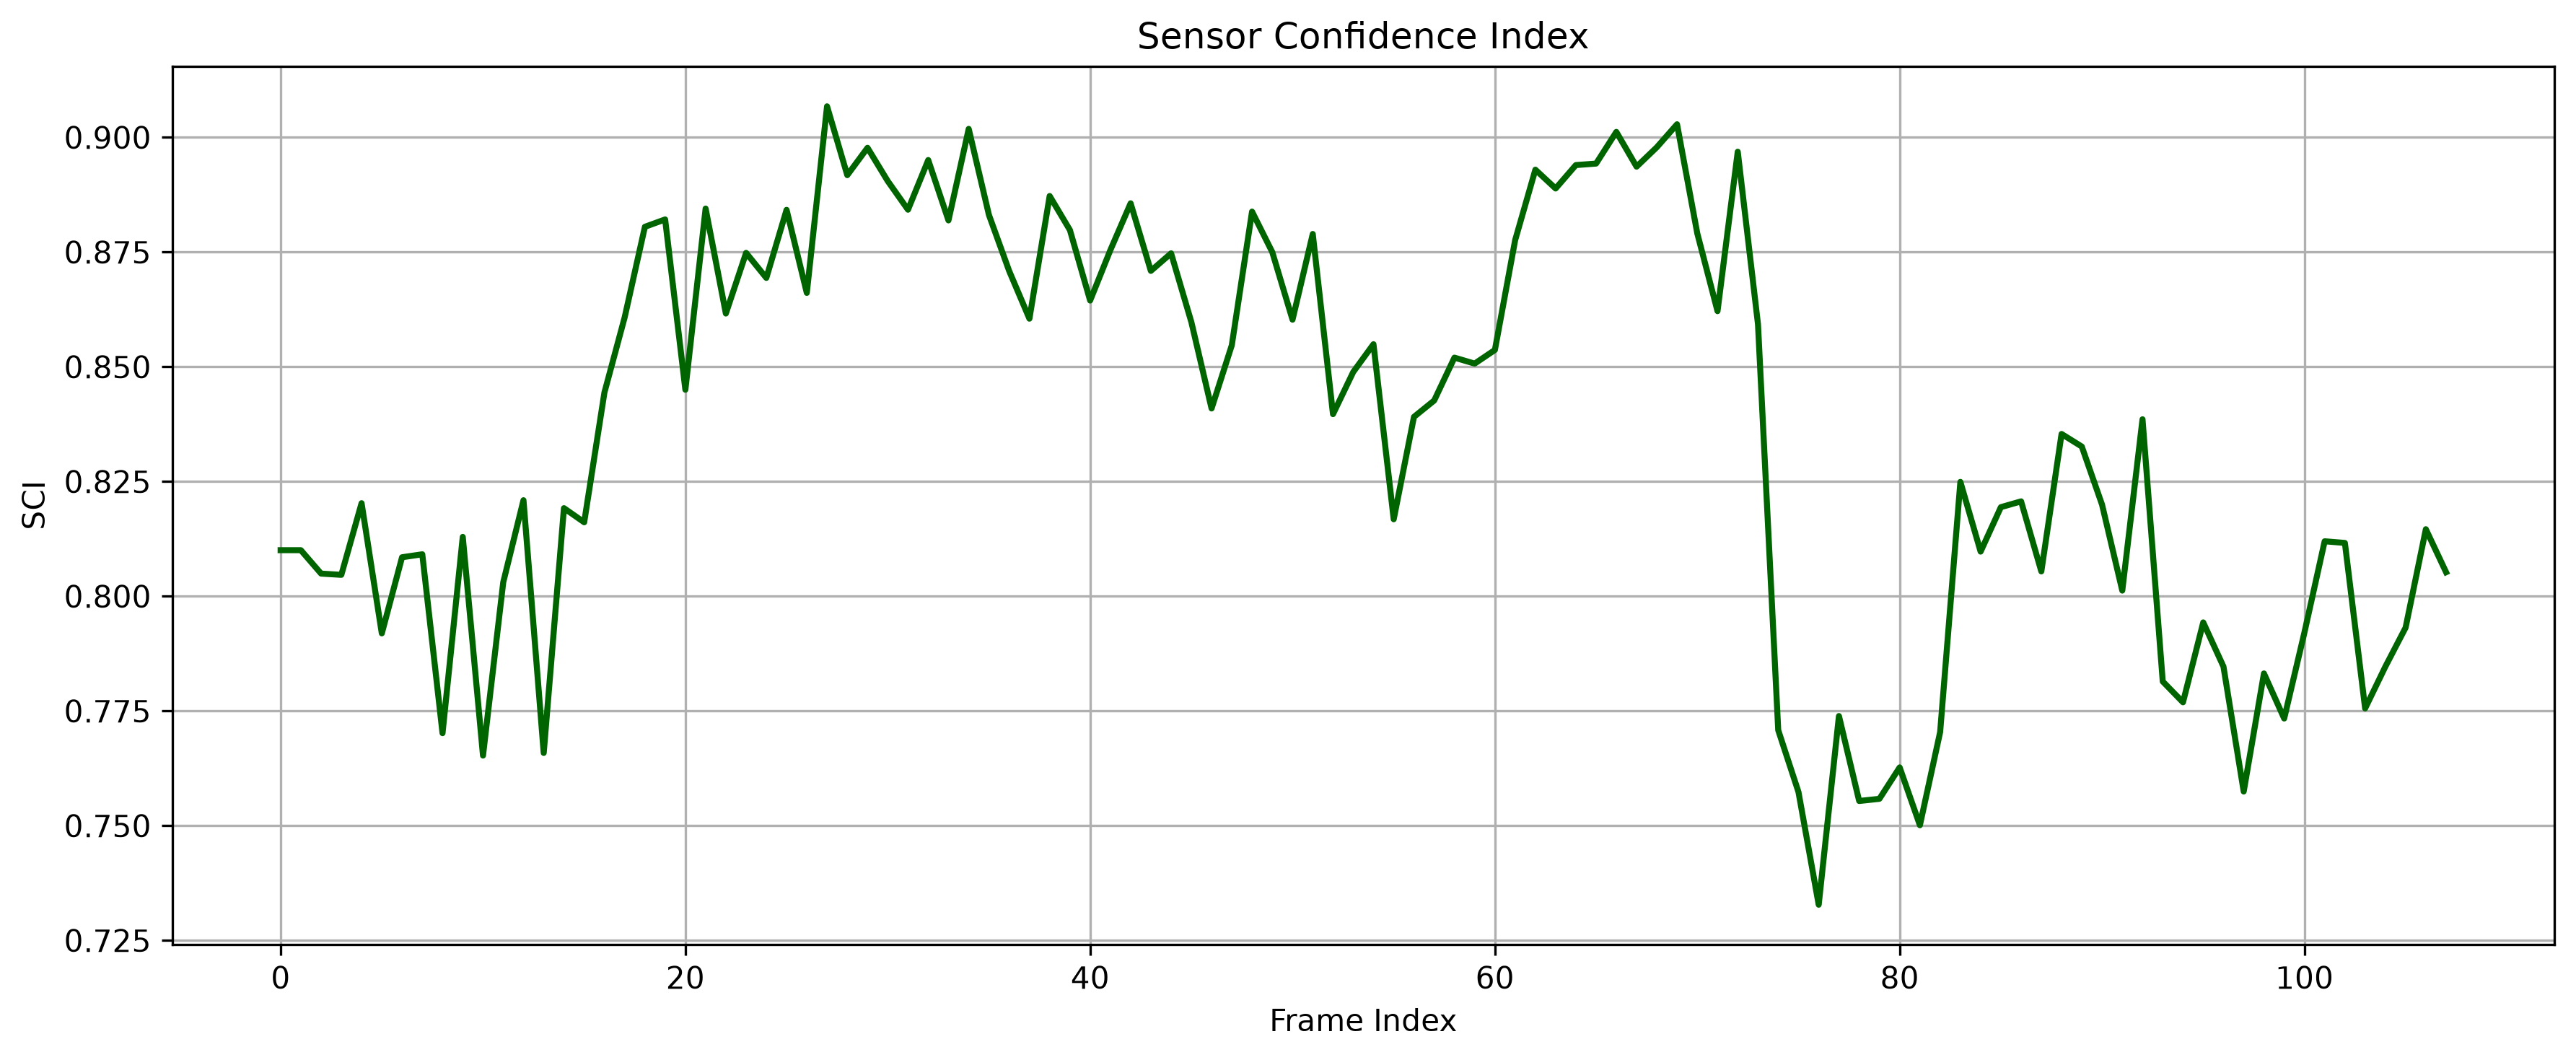

In [10]:
# ============================================================
# Cell 10
# Sensor Confidence Index
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(
    sci.index,
    sci["Sensor Confidence Index"],
    linewidth=2,
    color="darkgreen"
)

plt.xlabel("Frame Index")
plt.ylabel("SCI")

plt.title("Sensor Confidence Index")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Figure_04_SCI.png",
    dpi=300
)

plt.show()

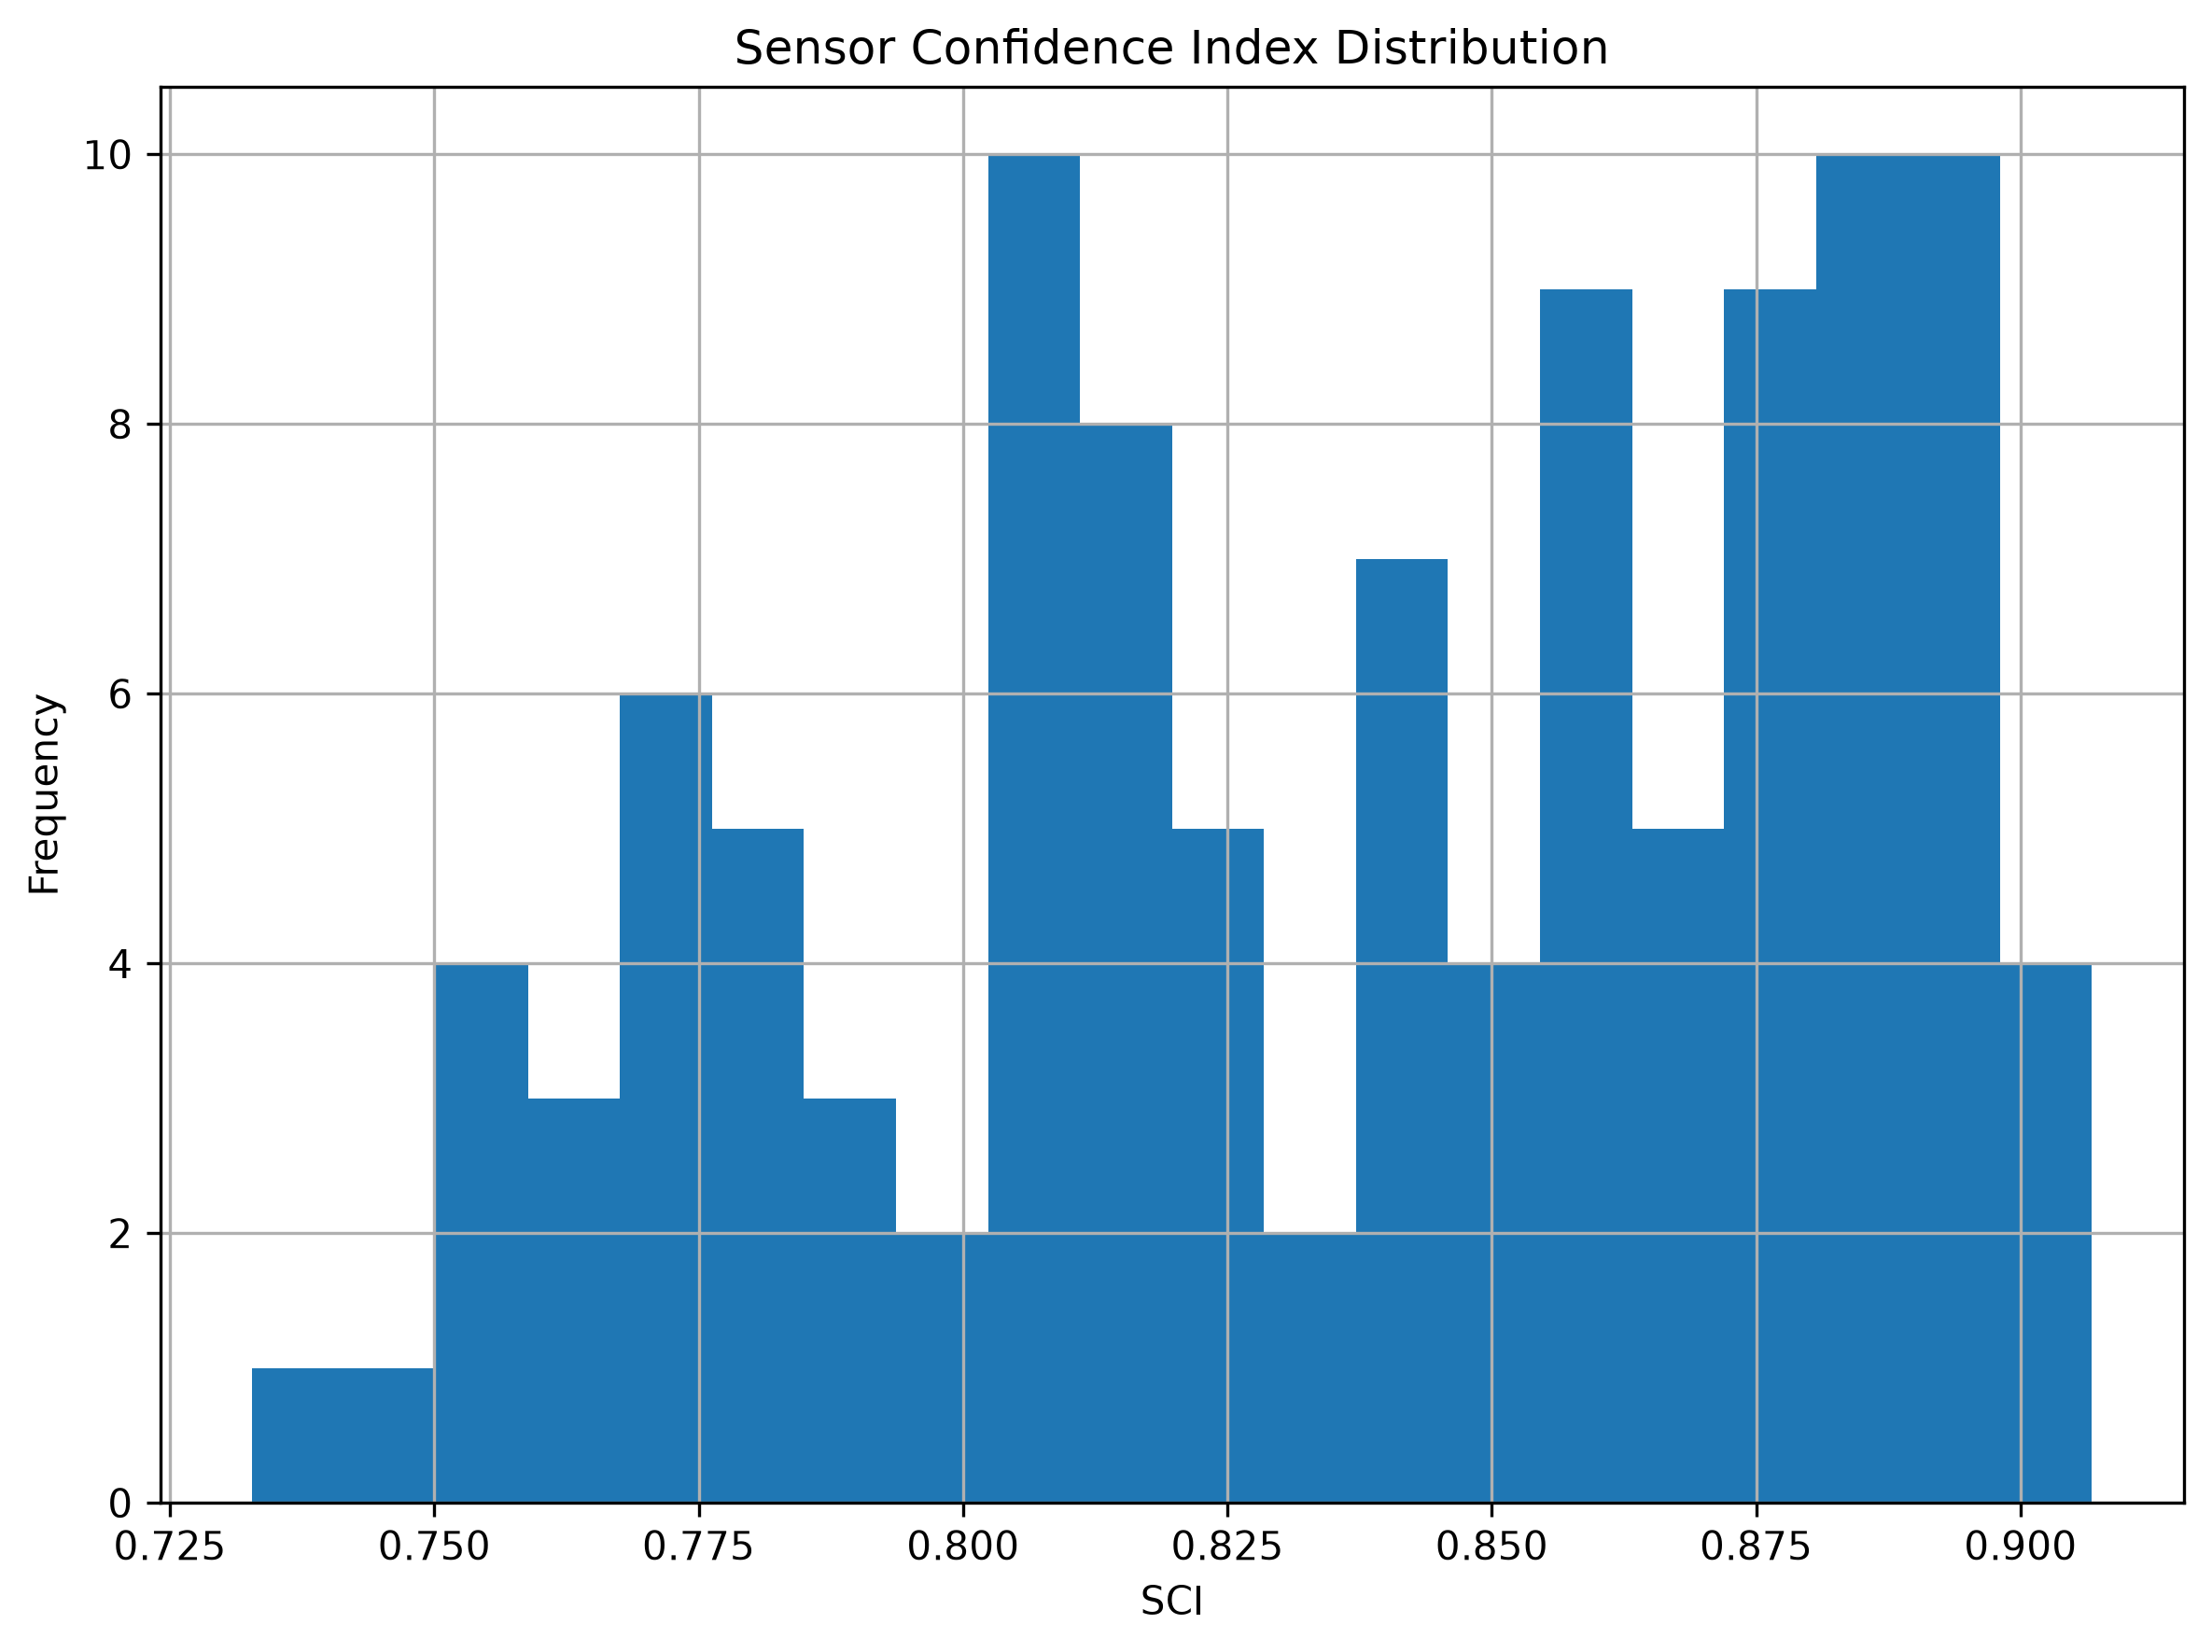

In [11]:
# ============================================================
# Cell 11
# SCI Distribution
# ============================================================

plt.figure(figsize=(8,6))

plt.hist(
    sci["Sensor Confidence Index"],
    bins=20
)

plt.xlabel("SCI")
plt.ylabel("Frequency")
plt.title("Sensor Confidence Index Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Figure_05_SCI_Distribution.png",
    dpi=300
)

plt.show()

,GPS Confidence,IMU Confidence,Sensor Confidence Index
GPS Confidence,1.000000,0.088401,0.942530
IMU Confidence,0.088401,1.000000,0.416135
Sensor Confidence Index,0.942530,0.416135,1.000000


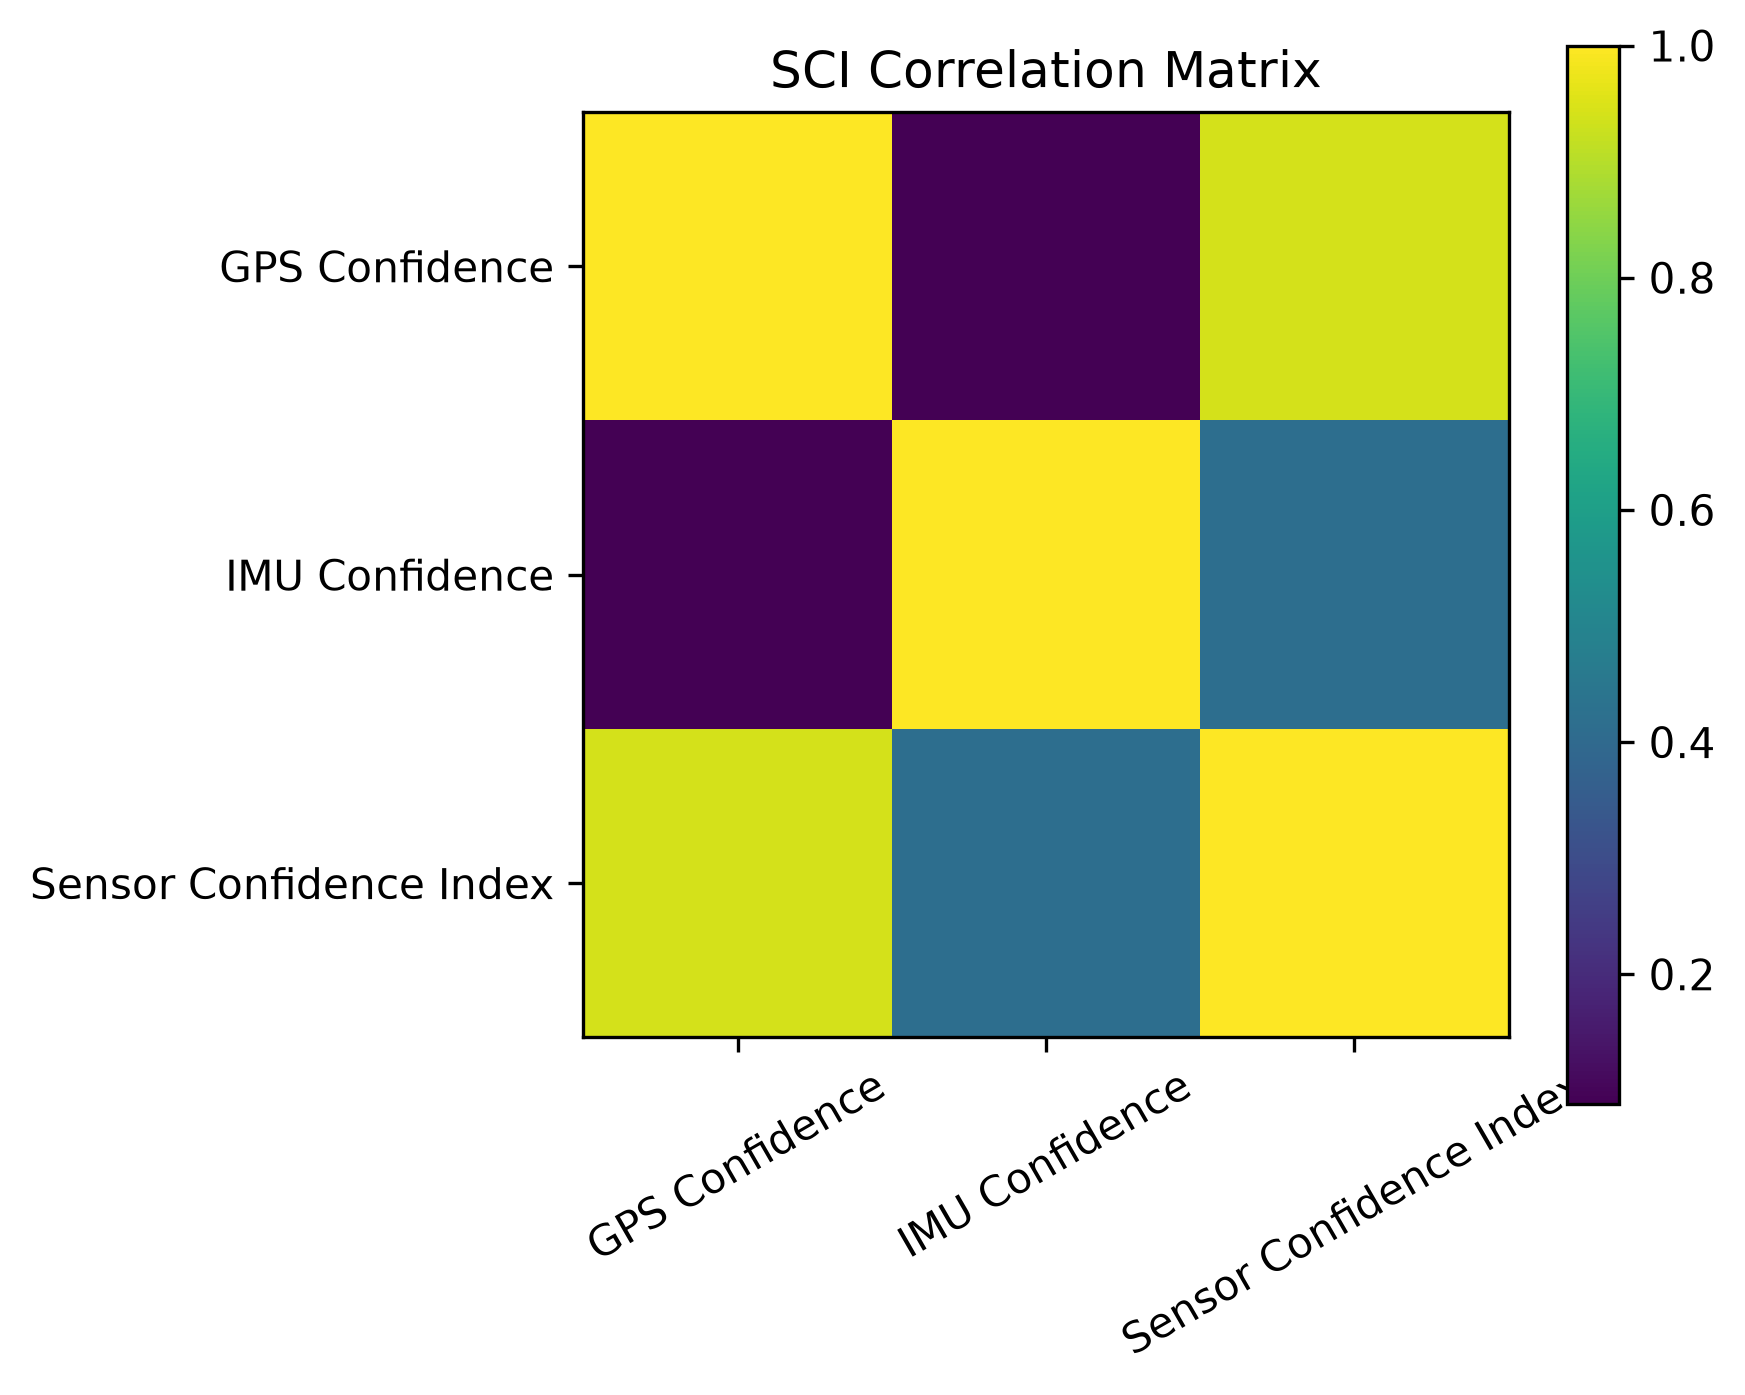

In [12]:
# ============================================================
# Cell 12
# SCI Correlation Matrix
# ============================================================

corr = sci[[
    "GPS Confidence",
    "IMU Confidence",
    "Sensor Confidence Index"
]].corr()

display(corr)

corr.to_csv(
    TABLE_DIR / "SCI_Correlation.csv"
)

plt.figure(figsize=(6,5))

plt.imshow(corr)

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=30
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("SCI Correlation Matrix")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Figure_06_SCI_Correlation.png",
    dpi=300
)

plt.show()

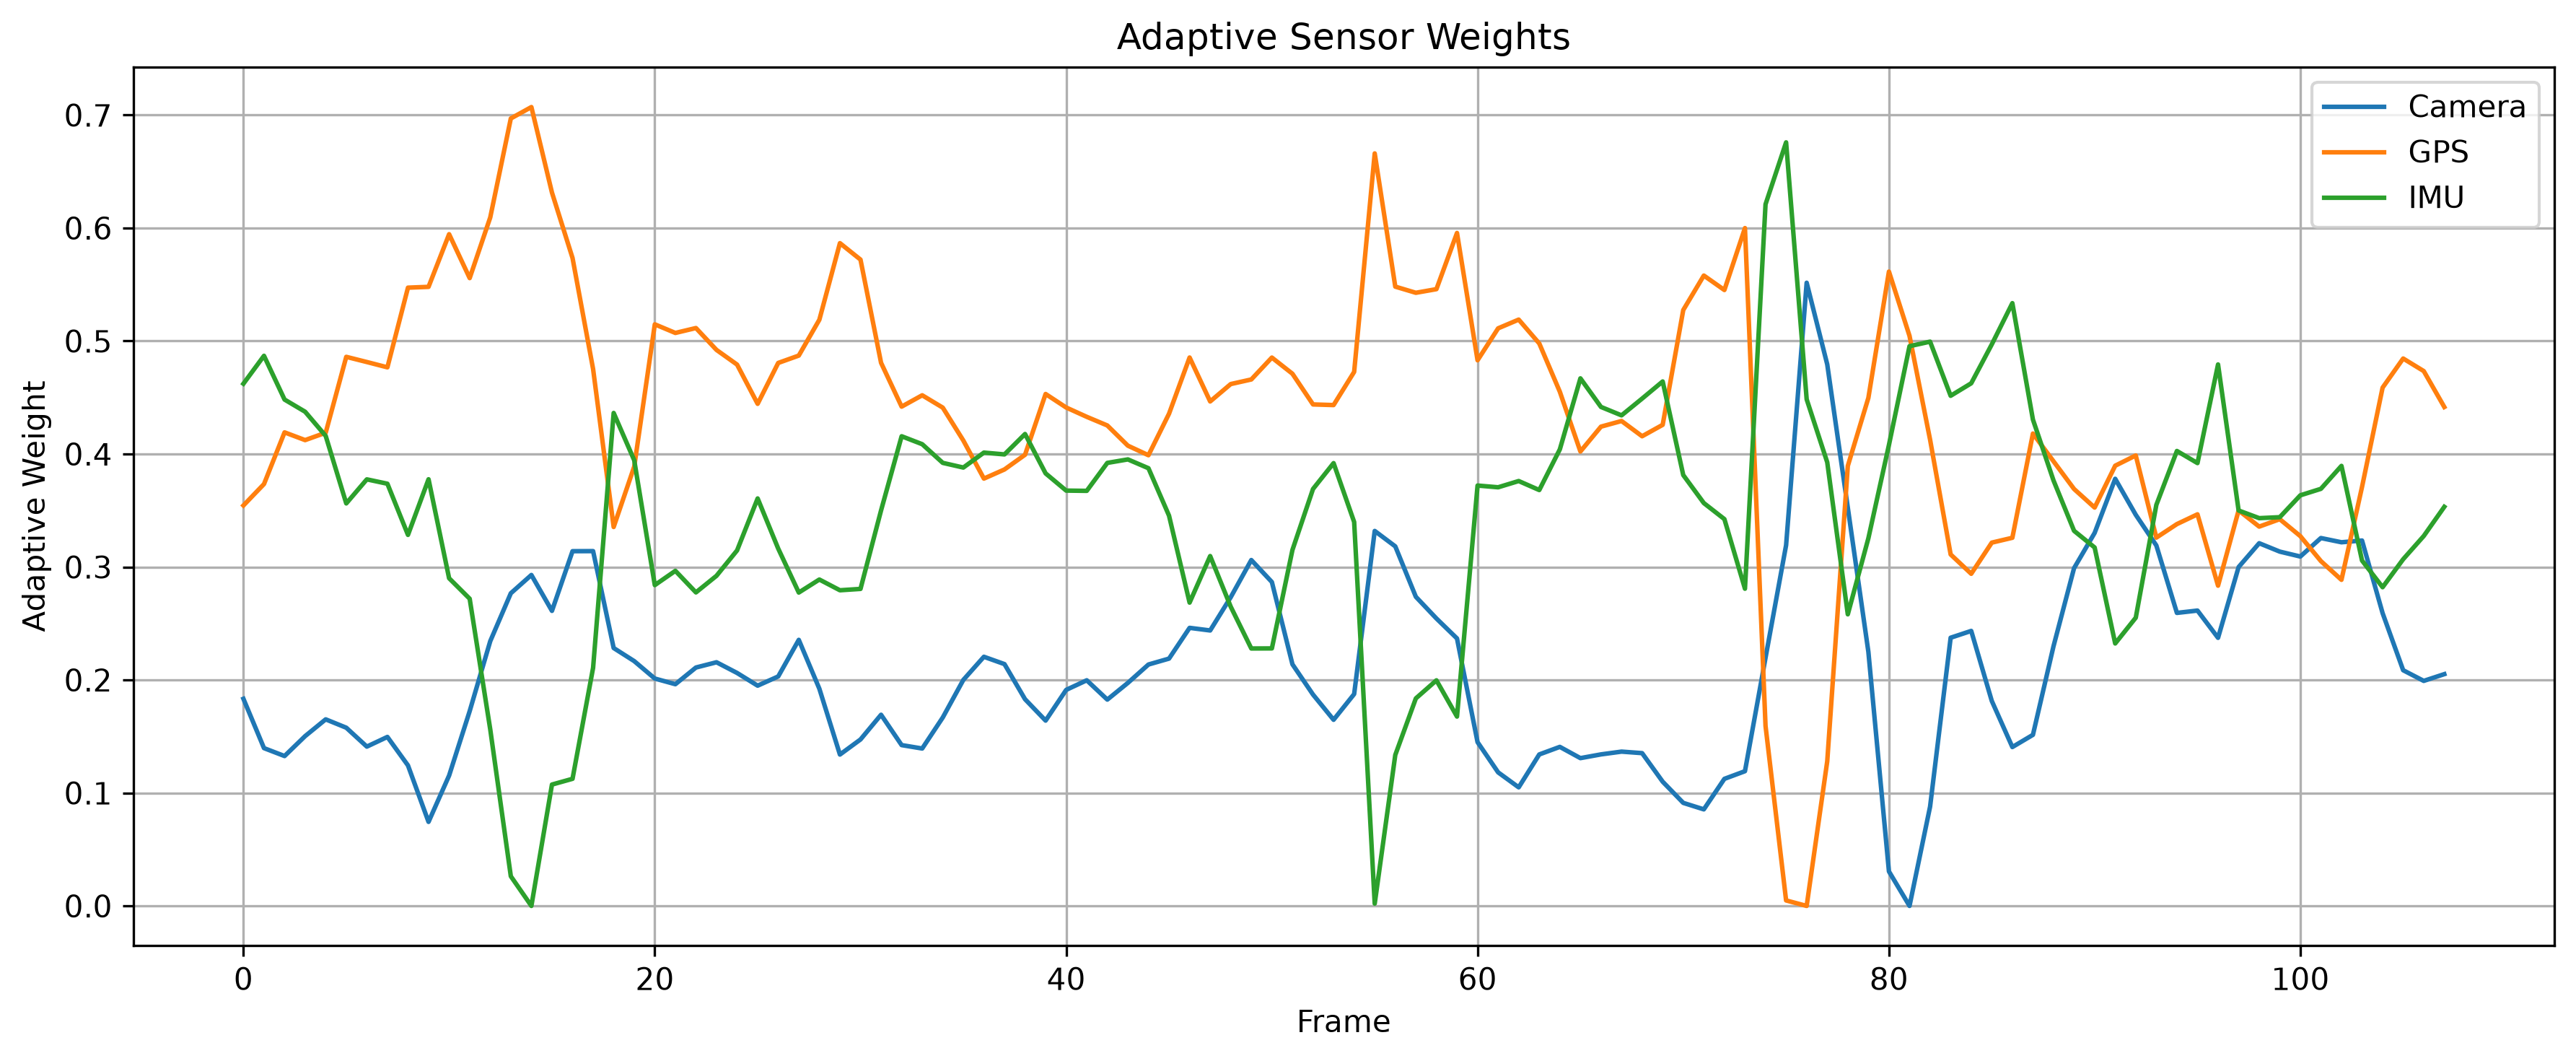

In [13]:
# ============================================================
# Cell 13
# Adaptive Weight Evolution
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(

weights["Frame"],

weights["Camera Weight"],

label="Camera"

)

plt.plot(

weights["Frame"],

weights["GPS Weight"],

label="GPS"

)

plt.plot(

weights["Frame"],

weights["IMU Weight"],

label="IMU"

)

plt.xlabel("Frame")

plt.ylabel("Adaptive Weight")

plt.title("Adaptive Sensor Weights")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(

FIGURE_DIR/

"Figure_07_Adaptive_Weights.png",

dpi=300

)

plt.show()

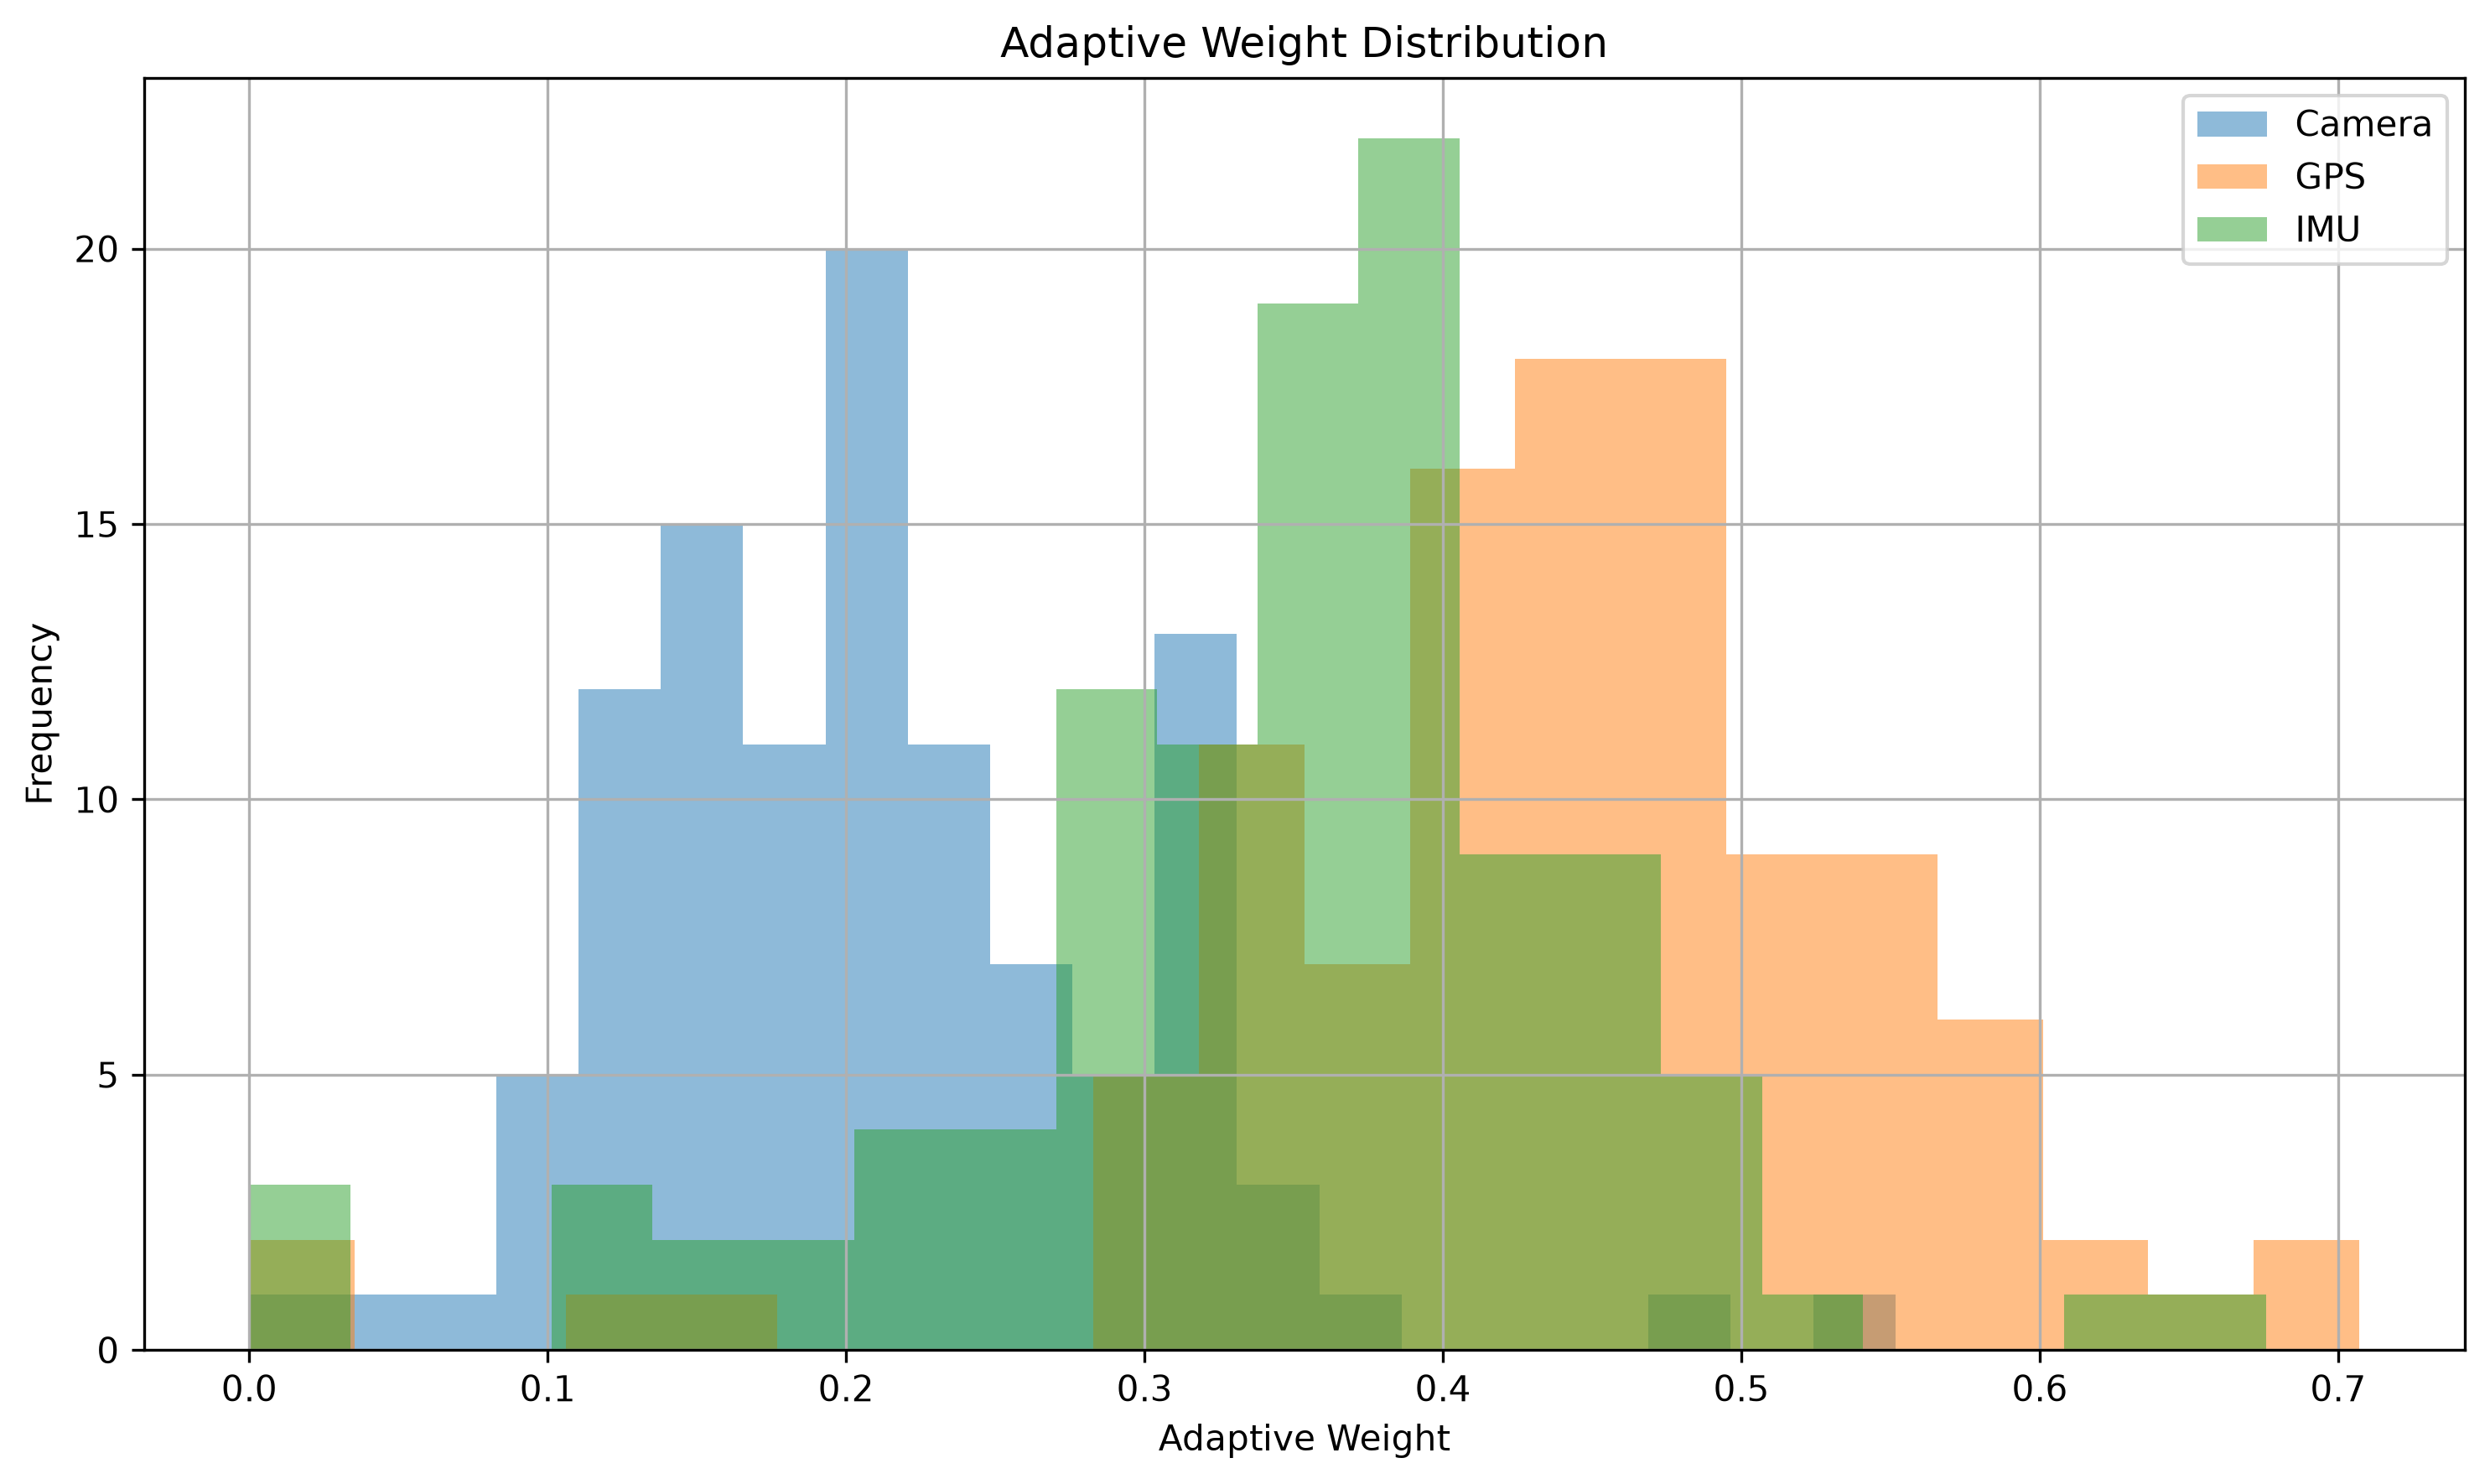

In [14]:
# ============================================================
# Cell 14
# Weight Distribution
# ============================================================

plt.figure(figsize=(10,6))

plt.hist(

weights["Camera Weight"],

alpha=0.5,

bins=20,

label="Camera"

)

plt.hist(

weights["GPS Weight"],

alpha=0.5,

bins=20,

label="GPS"

)

plt.hist(

weights["IMU Weight"],

alpha=0.5,

bins=20,

label="IMU"

)

plt.xlabel("Adaptive Weight")

plt.ylabel("Frequency")

plt.title("Adaptive Weight Distribution")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(

FIGURE_DIR/

"Figure_08_Weight_Distribution.png",

dpi=300

)

plt.show()

In [15]:
# ============================================================
# Cell 15
# Adaptive Weight Statistics
# ============================================================

weight_stats = weights[[
    "Camera Weight",
    "GPS Weight",
    "IMU Weight"
]].describe()

display(weight_stats)

weight_stats.to_csv(

TABLE_DIR/

"adaptive_weight_statistics.csv"

)

,Camera Weight,GPS Weight,IMU Weight
count,1.080000e+02,1.080000e+02,1.080000e+02
mean,2.127216e-01,4.406545e-01,3.466239e-01
std,8.620692e-02,1.145378e-01,1.097900e-01
min,3.468902e-08,1.077500e-07,1.451772e-07
25%,1.467390e-01,3.892937e-01,2.897537e-01
50%,2.041369e-01,4.441347e-01,3.654112e-01
75%,2.612279e-01,5.052087e-01,4.030376e-01
max,5.515855e-01,7.070770e-01,6.758544e-01


,Frame,Camera Confidence,GPS Confidence,IMU Confidence,Camera Confidence Stability,GPS Confidence Stability,IMU Confidence Stability,Camera Confidence Reliability,GPS Confidence Reliability,IMU Confidence Reliability,Camera Weight,GPS Weight,IMU Weight,Weight Sum,Fused Confidence,Smoothed Confidence,Confidence Std,Normalized Std,Stability Confidence,Localization Reliability Score
count,108.00000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,1.080000e+02,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000
mean,53.50000,0.407729,0.581366,0.743690,0.075676,0.068393,0.158885,0.251363,0.513837,0.425195,0.216575,0.424380,0.359045,1.000000e+00,0.697491,0.696650,0.026252,0.256261,0.704513,0.699795
std,31.32092,0.270209,0.303771,0.190172,0.045765,0.087060,0.072355,0.186665,0.280385,0.194058,0.158060,0.207270,0.151497,4.293172e-17,0.139037,0.116782,0.019233,0.187737,0.163768,0.100492
min,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.304064,0.397758,0.000000,0.000000,0.223130,0.475533
25%,26.75000,0.194217,0.345248,0.640359,0.043247,0.017918,0.111923,0.120343,0.304162,0.311971,0.113503,0.282824,0.266719,1.000000e+00,0.627632,0.654549,0.012947,0.126382,0.611032,0.645483
50%,53.50000,0.356431,0.732142,0.753984,0.063415,0.031629,0.155879,0.205757,0.537411,0.426378,0.168581,0.468606,0.360754,1.000000e+00,0.711395,0.711867,0.020607,0.201150,0.739542,0.721406
75%,80.25000,0.606354,0.810752,0.896143,0.104959,0.092970,0.194572,0.341017,0.758891,0.561044,0.285453,0.580124,0.435613,1.000000e+00,0.794759,0.774567,0.033643,0.328405,0.827312,0.770237
max,107.00000,1.000000,1.000000,1.000000,0.218829,0.465255,0.355336,0.820675,0.967786,0.866675,0.774826,0.801296,0.860470,1.000000e+00,0.938943,0.887224,0.102444,1.000000,1.000000,0.870884


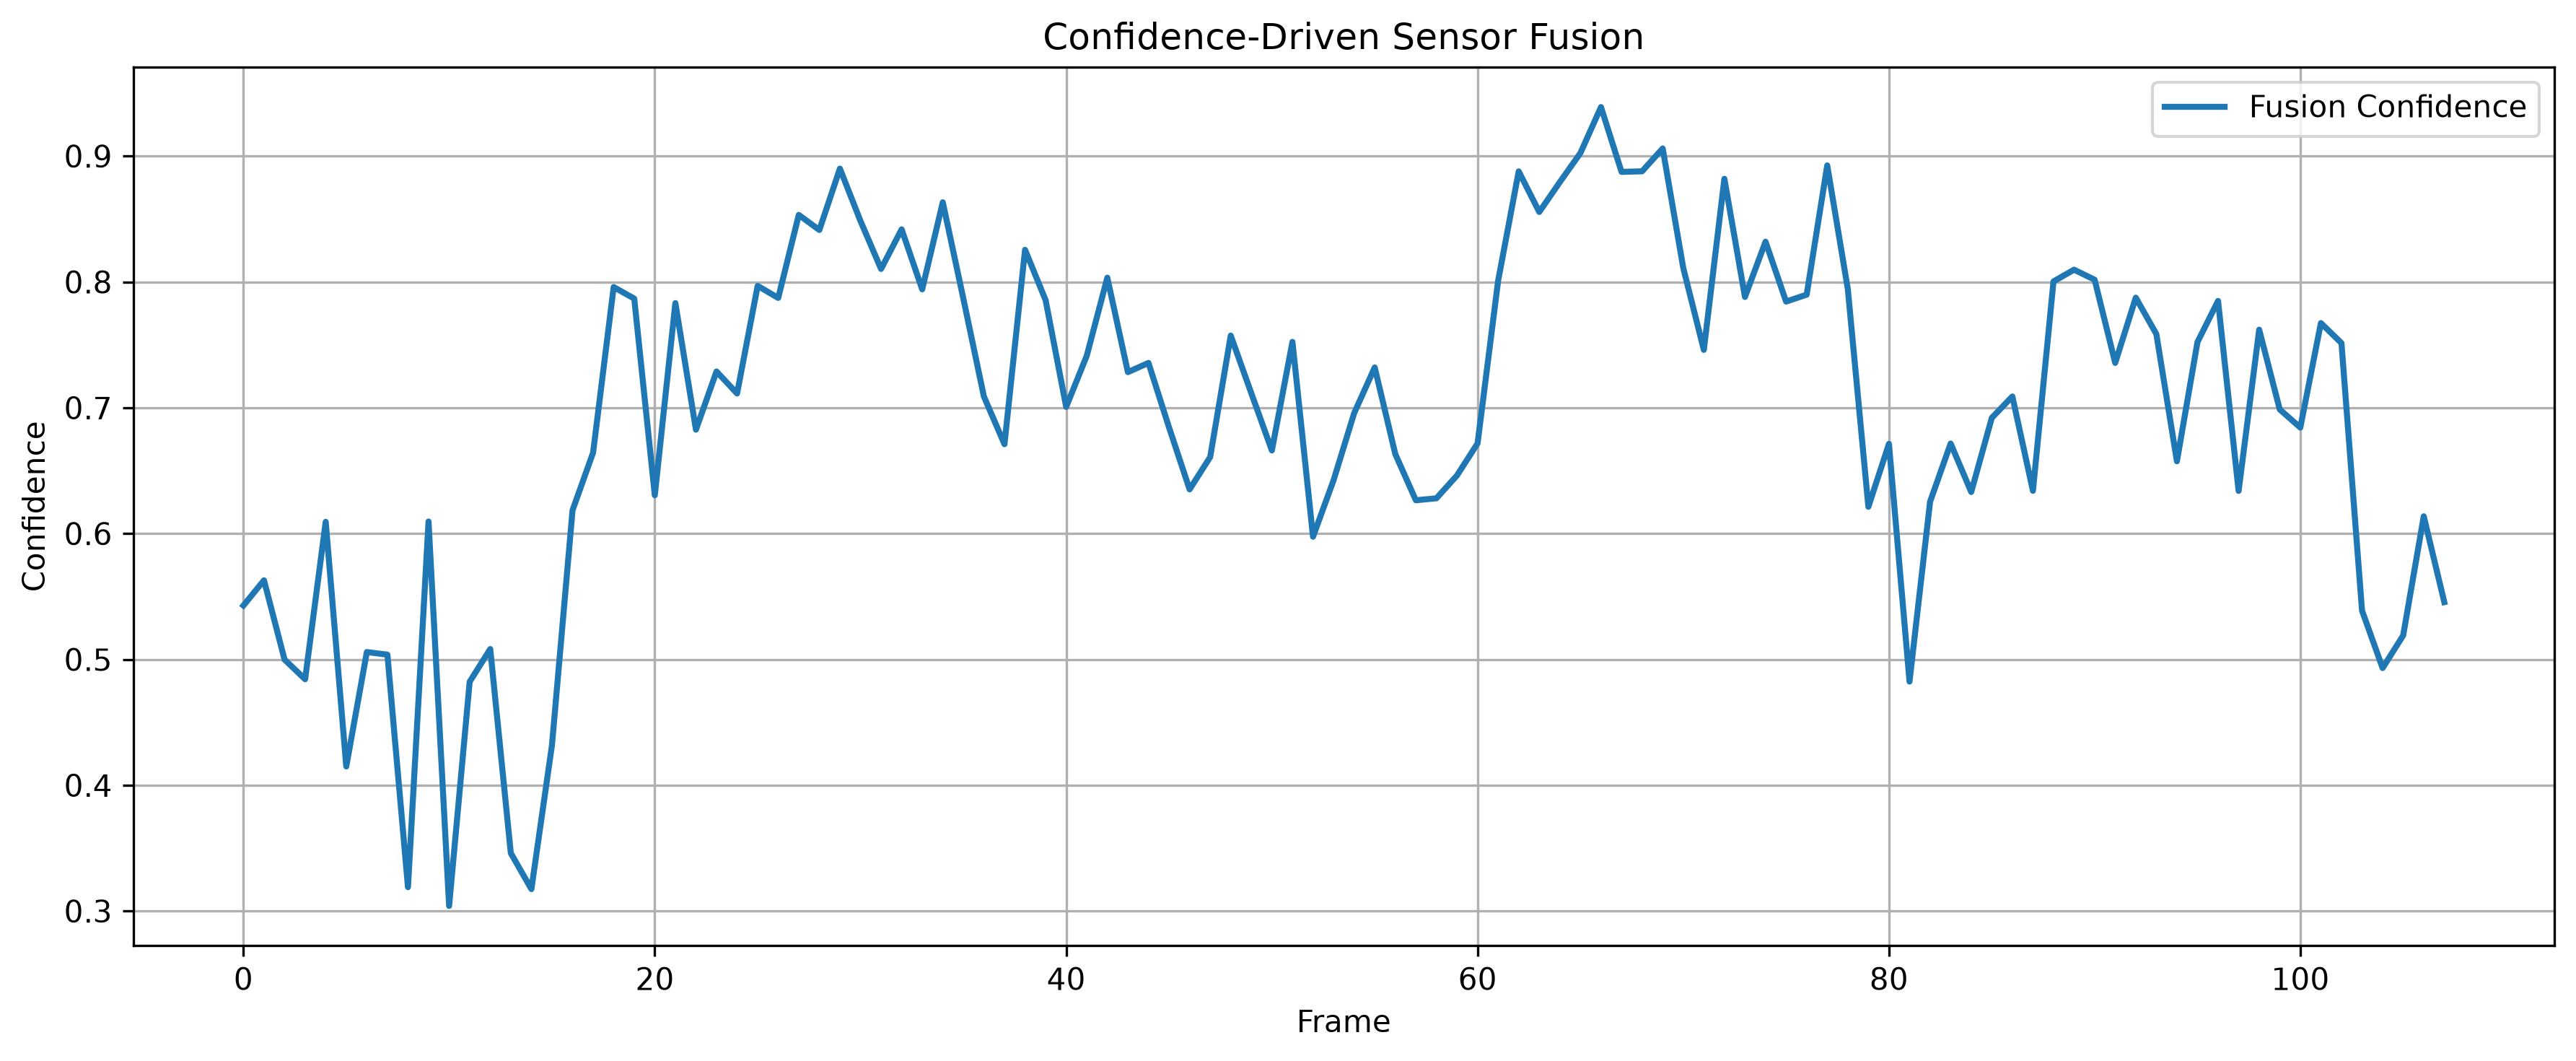

In [16]:
# ============================================================
# Cell 16
# Confidence-Driven Sensor Fusion
# ============================================================

fusion_stats = fusion.describe()

display(fusion_stats)

fusion_stats.to_csv(
    TABLE_DIR /
    "fusion_statistics.csv"
)

plt.figure(figsize=(12,5))

plt.plot(
    fusion["Frame"],
    fusion["Fused Confidence"],
    linewidth=2,
    label="Fusion Confidence"
)

plt.xlabel("Frame")

plt.ylabel("Confidence")

plt.title("Confidence-Driven Sensor Fusion")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure_09_Fusion_Confidence.png",
    dpi=300
)

plt.show()

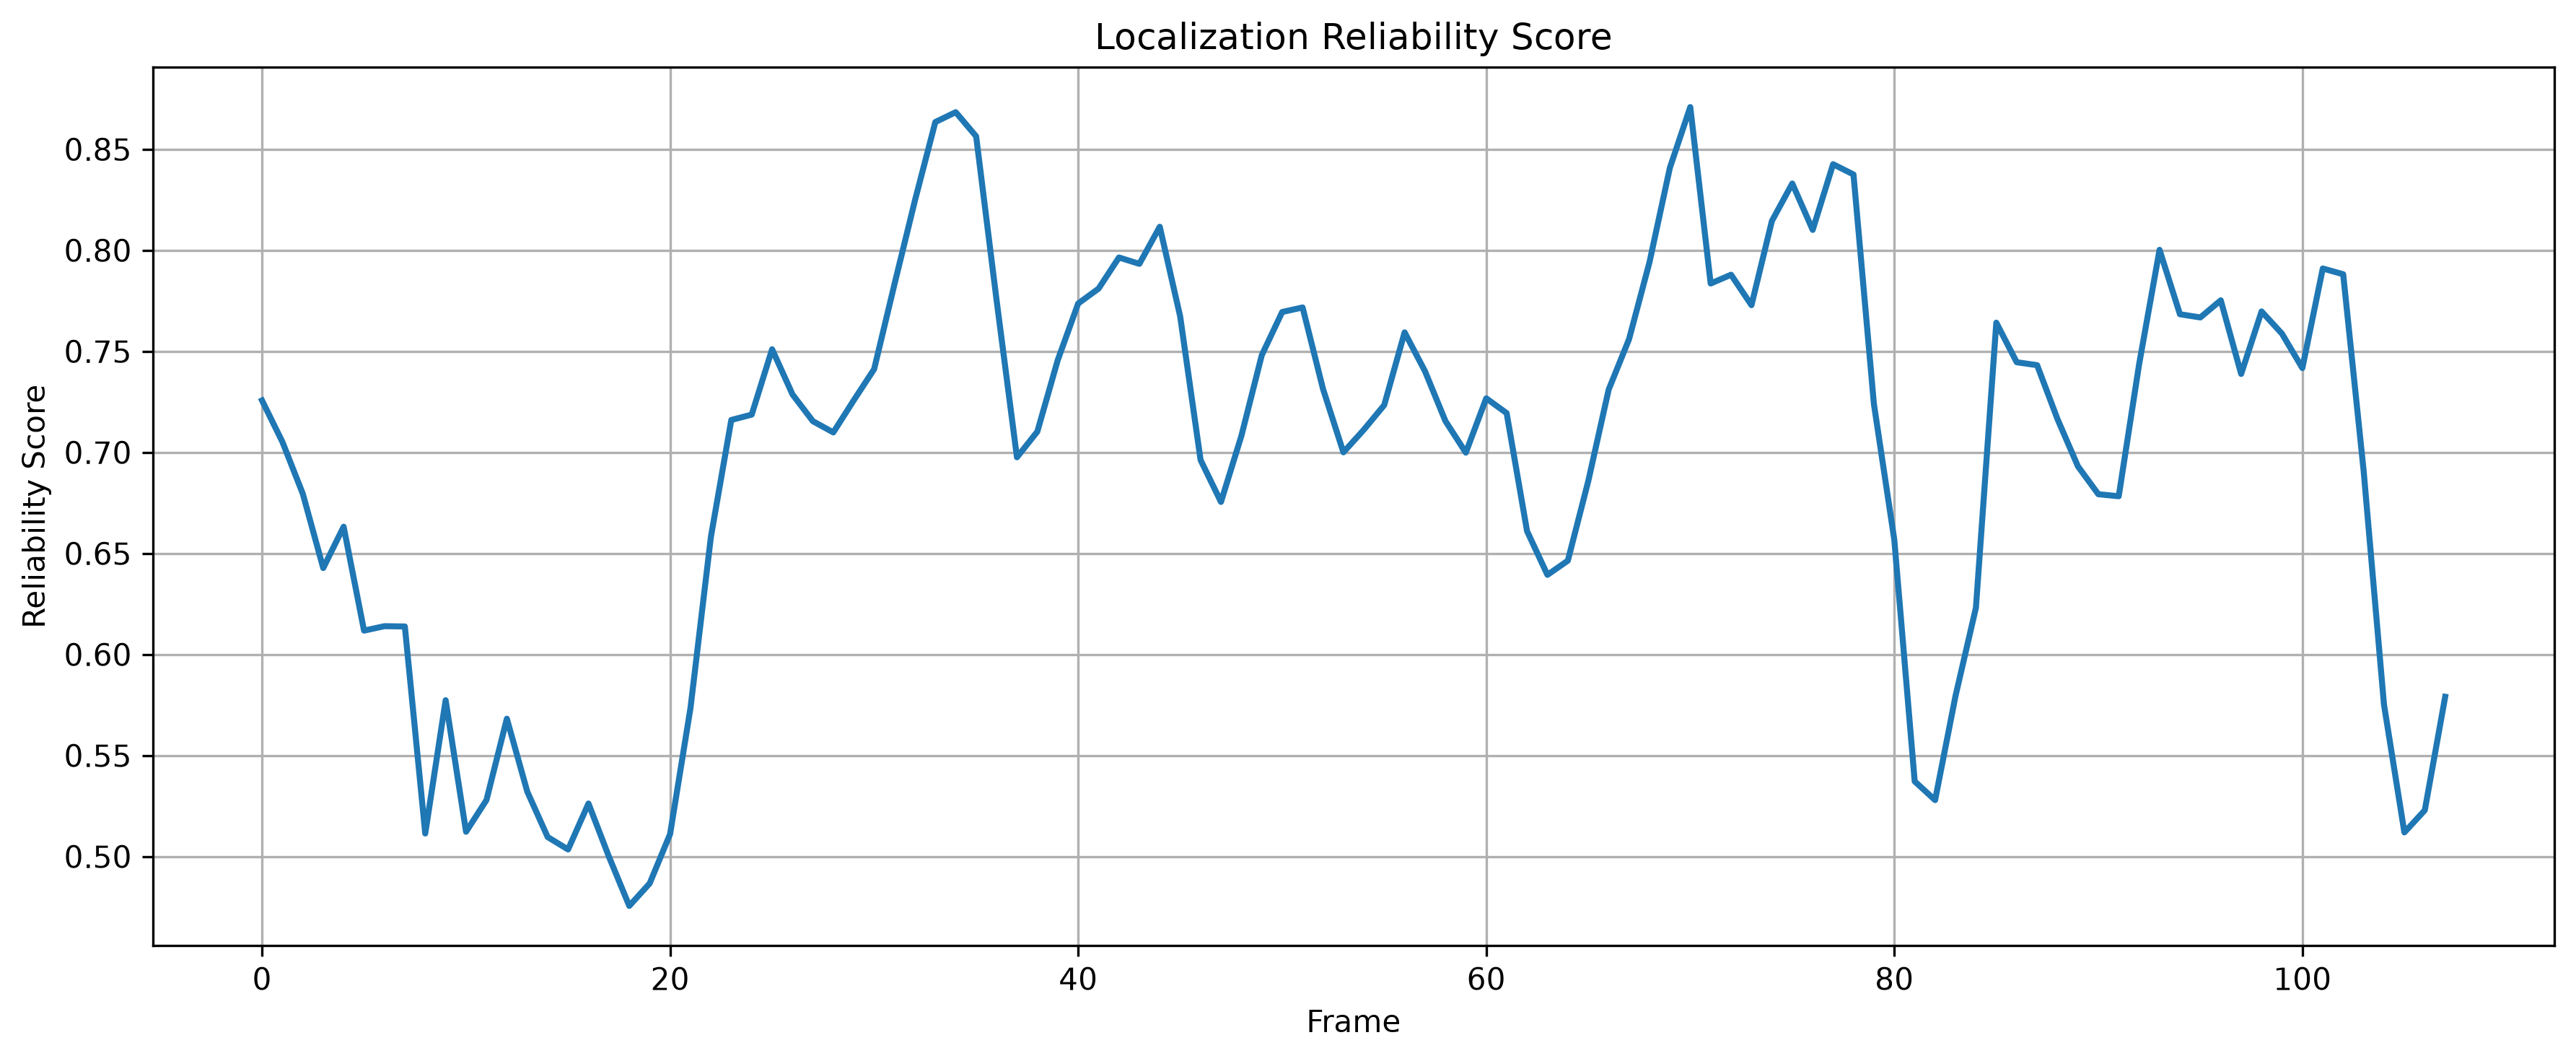

In [17]:
# ============================================================
# Cell 17
# Localization Reliability
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(
    fusion["Frame"],
    fusion["Localization Reliability Score"],
    linewidth=2
)

plt.xlabel("Frame")

plt.ylabel("Reliability Score")

plt.title("Localization Reliability Score")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure_10_Localization_Reliability.png",
    dpi=300
)

plt.show()

Localization Level
Moderate     32
Low          32
High         22
Poor         11
Excellent    11
Name: count, dtype: int64

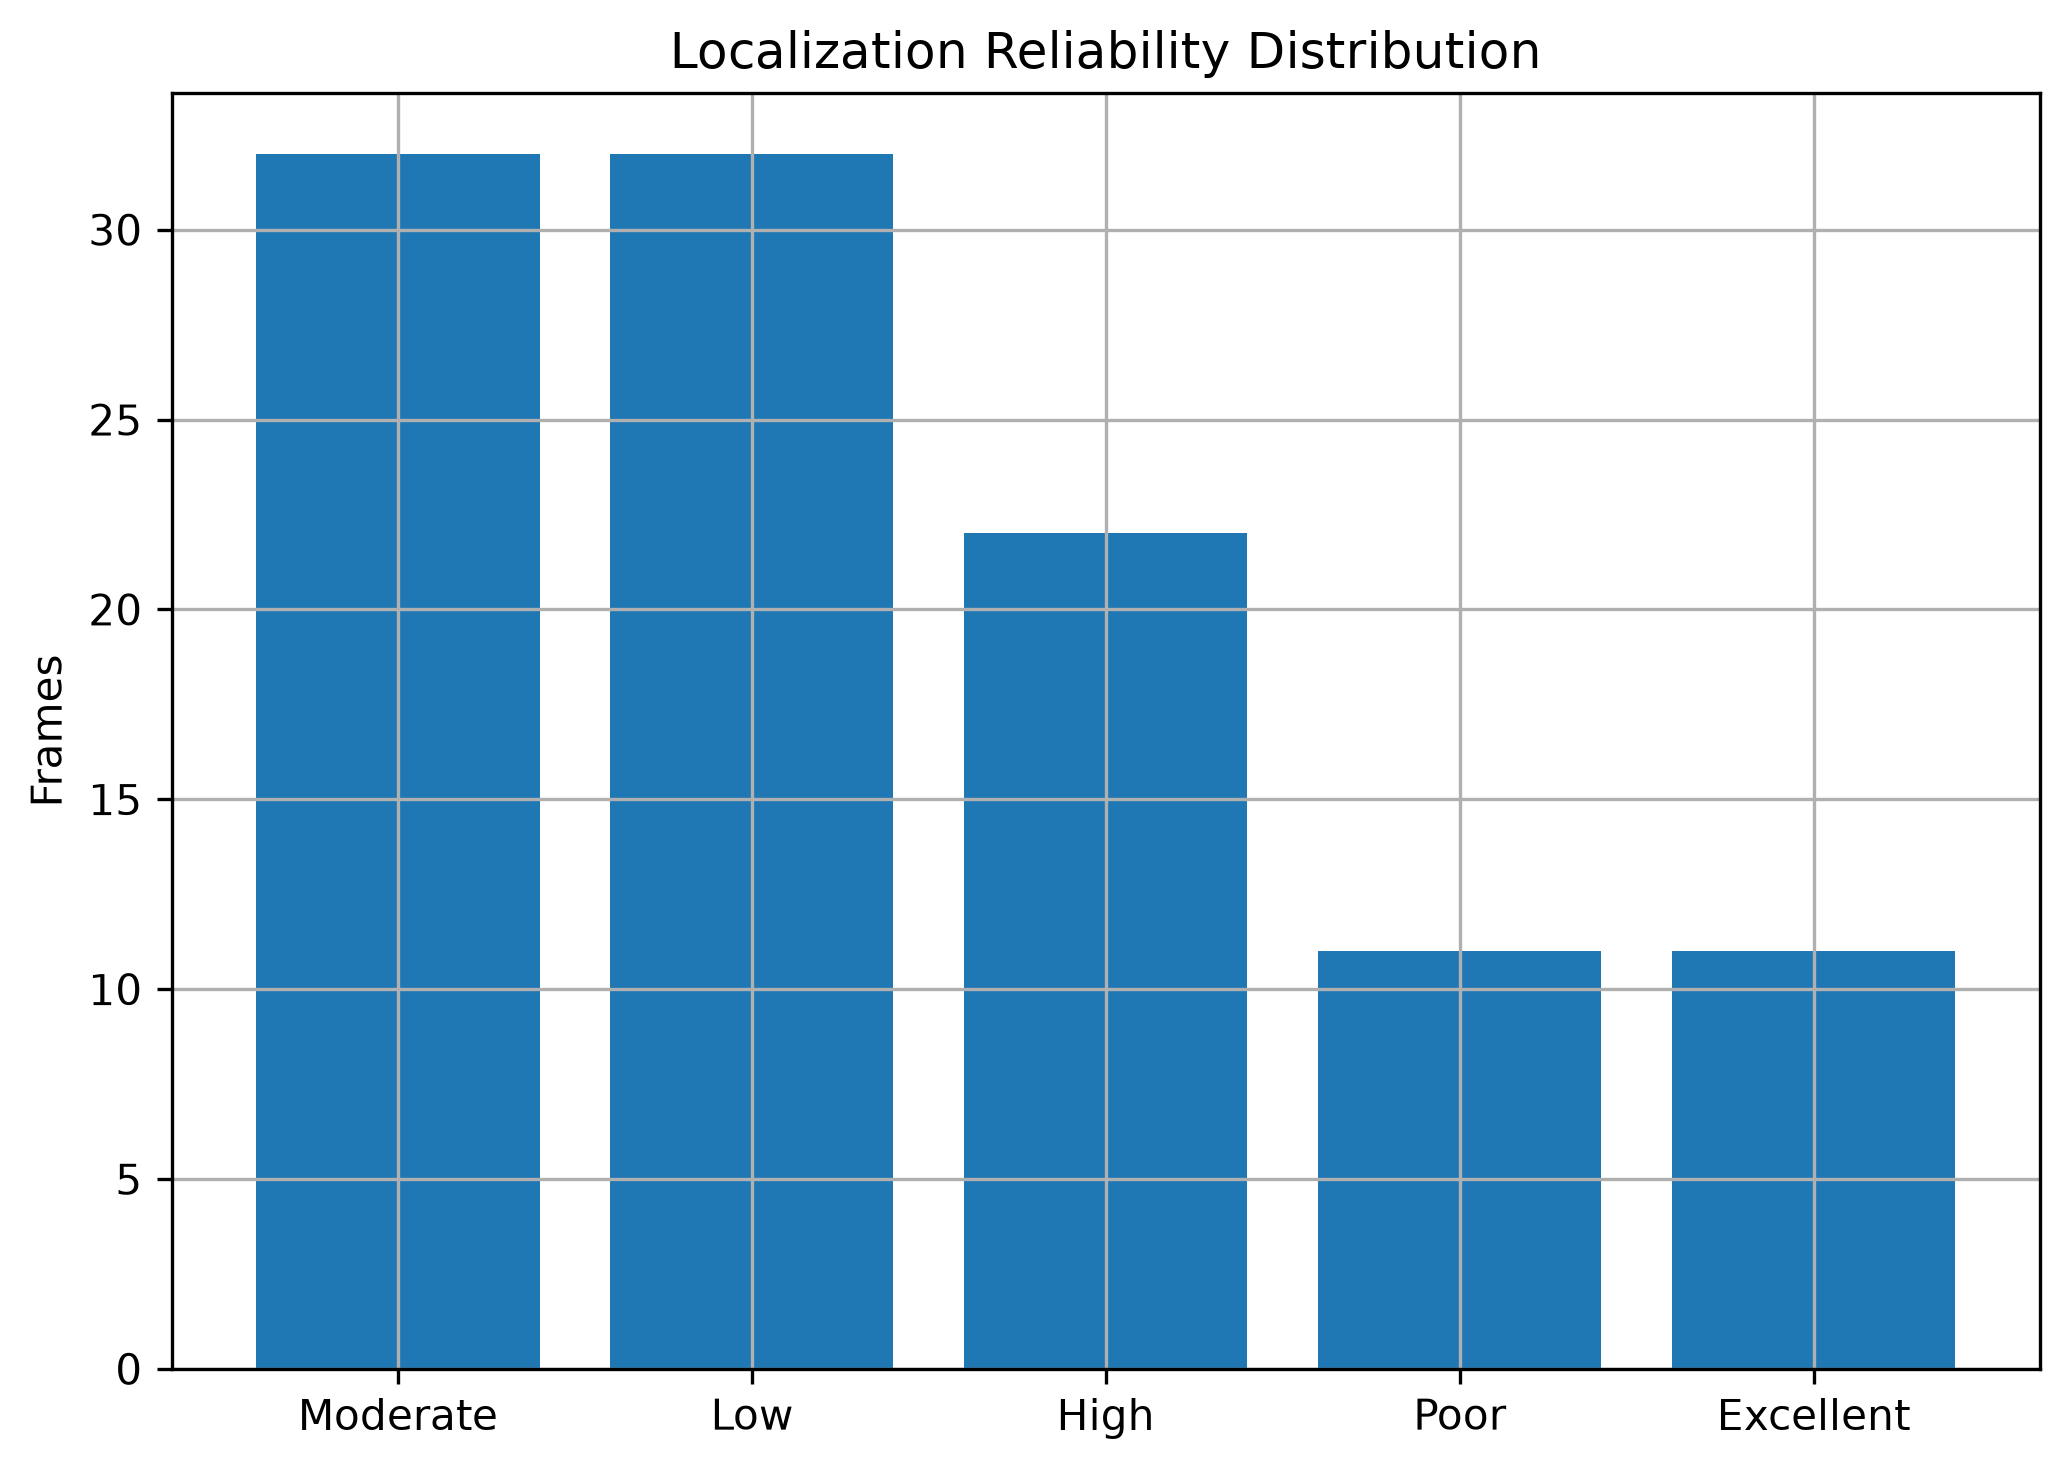

In [18]:
# ============================================================
# Cell 18
# Reliability Distribution
# ============================================================

counts = fusion["Localization Level"].value_counts()

display(counts)

counts.to_csv(
    TABLE_DIR /
    "localization_level_distribution.csv"
)

plt.figure(figsize=(7,5))

plt.bar(
    counts.index,
    counts.values
)

plt.ylabel("Frames")

plt.title("Localization Reliability Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure_11_Reliability_Distribution.png",
    dpi=300
)

plt.show()

,Frame,X,Y,Velocity,Heading,Acceleration,Yaw Rate,Camera Weight,GPS Weight,IMU Weight,Localization Reliability Score,Estimated X,Estimated Y,Estimated Velocity,Estimated Heading,Innovation Norm,Covariance Trace,Position Error
count,108.00000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000
mean,53.50000,-54.364519,-26.866285,9.733995,-2.718472,9.852577,-0.013323,0.216575,0.424380,0.359045,0.699795,-55.282465,-27.317515,11.878477,-2.708870,11.100915,4.828099,1.023321
std,31.32092,29.151693,13.260452,2.357965,0.044789,0.141576,0.013673,0.158060,0.207270,0.151497,0.100492,29.405979,13.352157,0.868301,0.043640,9.942923,1.076415,0.288308
min,0.00000,-96.731737,-45.360361,4.612138,-2.754572,9.393870,-0.041515,0.000000,0.000000,0.000000,0.475533,-98.210417,-46.028739,10.093014,-2.744666,1.109771,2.663884,0.573203
25%,26.75000,-80.521040,-38.515045,7.963649,-2.751804,9.777824,-0.024341,0.113503,0.282824,0.266719,0.645483,-81.727740,-39.076292,11.206712,-2.741852,2.680405,3.468386,0.747374
50%,53.50000,-57.453910,-28.937892,10.321351,-2.746841,9.860408,-0.011342,0.168581,0.468606,0.360754,0.721406,-58.400026,-29.403854,12.064069,-2.736615,7.430756,5.259730,1.045544
75%,80.25000,-29.705091,-16.310304,11.596521,-2.690648,9.935109,0.000946,0.285453,0.580124,0.435613,0.770237,-30.215483,-16.583940,12.579370,-2.680722,17.693482,5.512096,1.247655
max,107.00000,0.000000,0.000000,13.173300,-2.608707,10.219657,0.005902,0.774826,0.801296,0.860470,0.870884,-0.709538,-0.417884,13.140990,-2.608715,35.336182,6.546686,1.671553


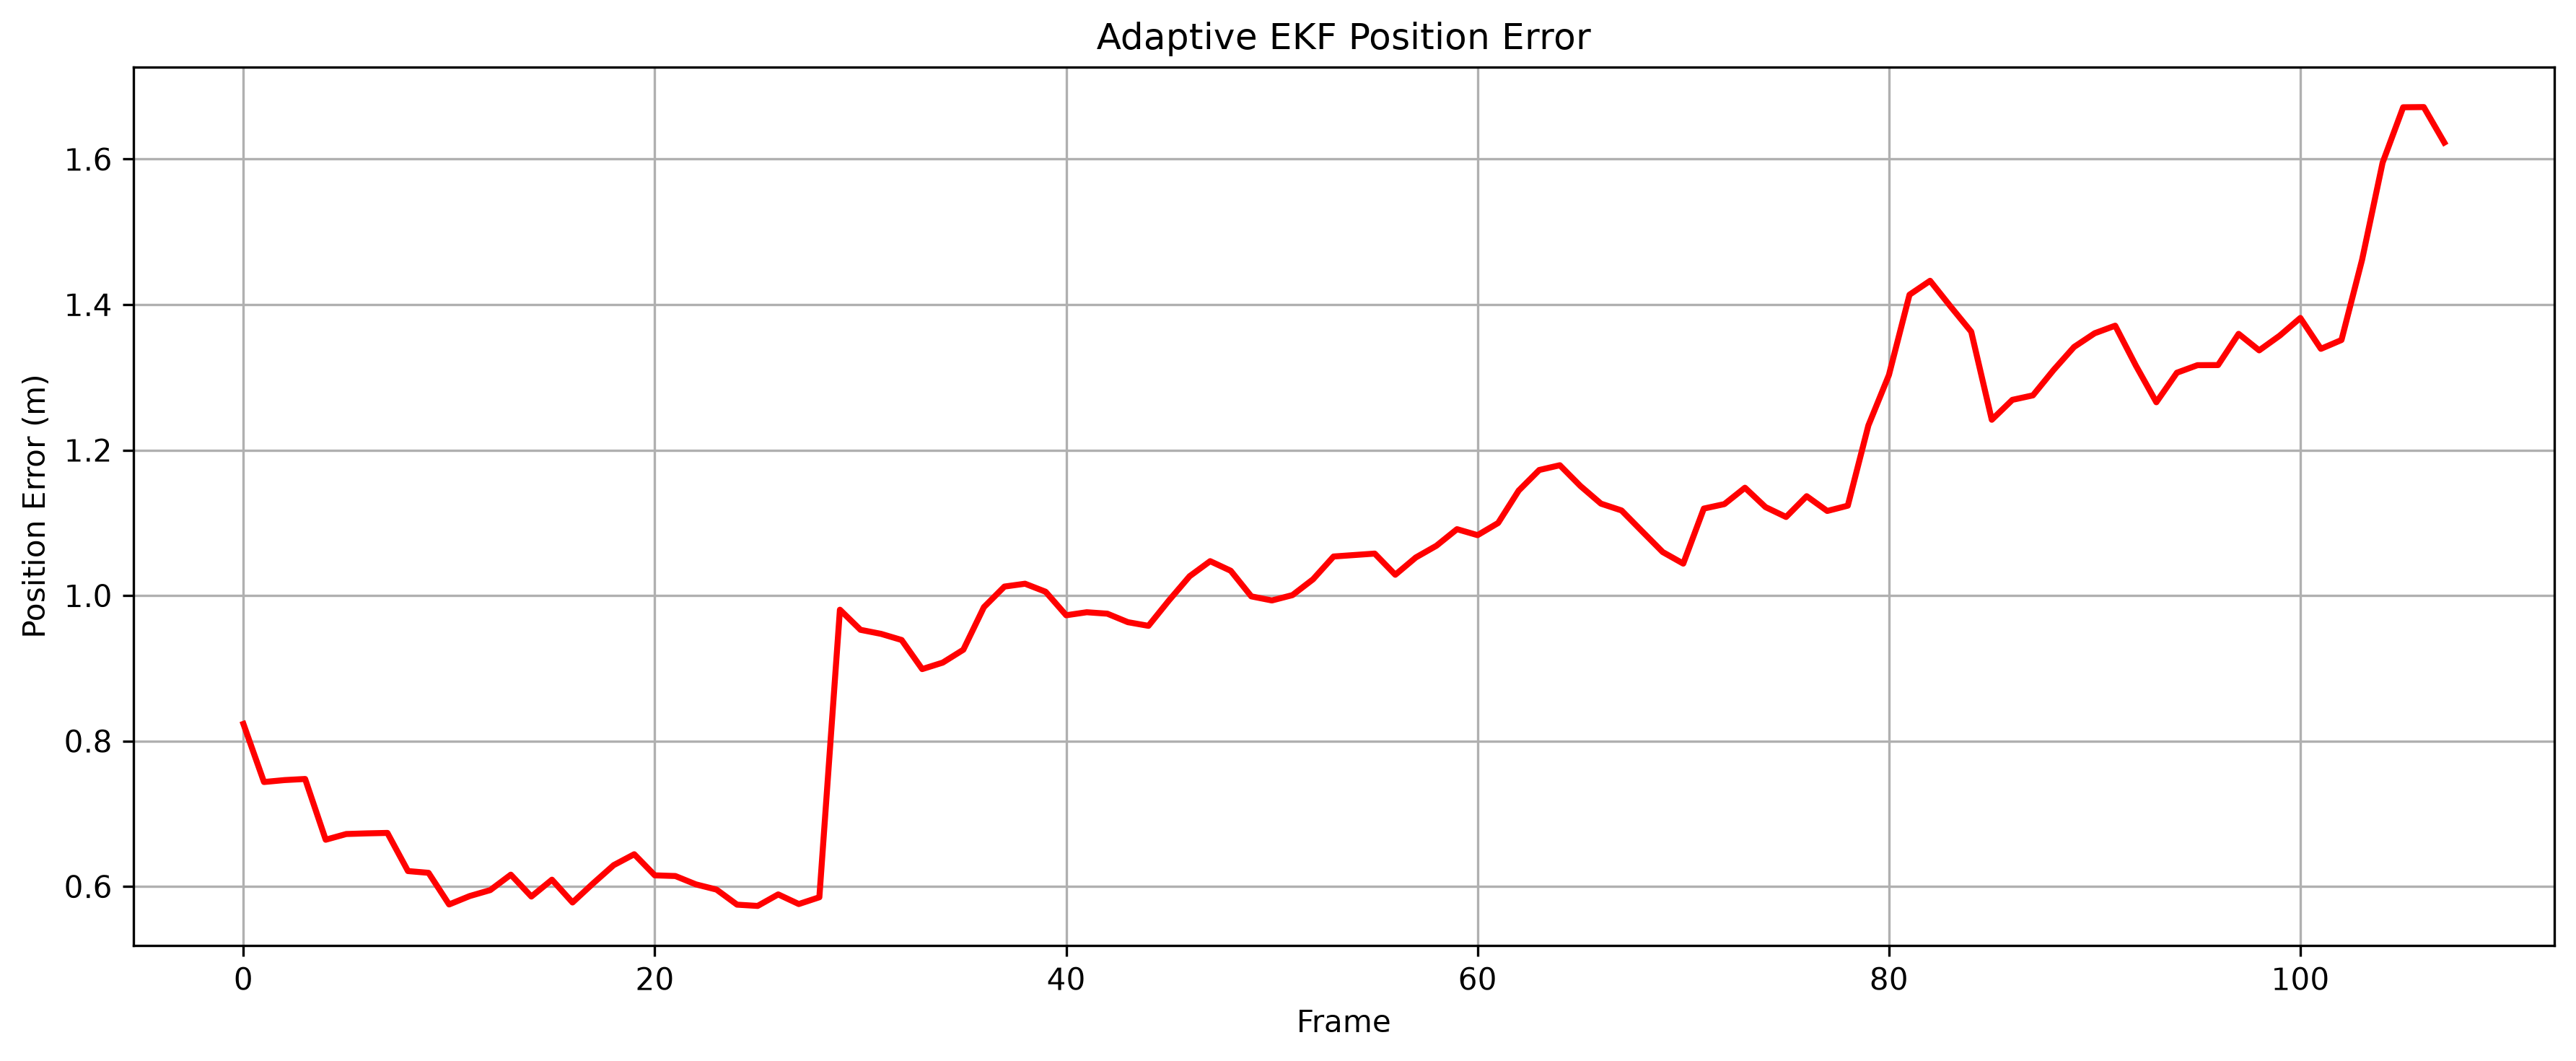

In [19]:
# ============================================================
# Cell 19
# Adaptive EKF Position Error
# ============================================================

ekf_stats = ekf.describe()

display(ekf_stats)

ekf_stats.to_csv(
    TABLE_DIR / "adaptive_ekf_statistics.csv"
)

plt.figure(figsize=(12,5))

plt.plot(
    ekf["Frame"],
    ekf["Position Error"],
    linewidth=2,
    color="red"
)

plt.xlabel("Frame")
plt.ylabel("Position Error (m)")

plt.title("Adaptive EKF Position Error")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Figure_12_EKF_Position_Error.png",
    dpi=300
)

plt.show()

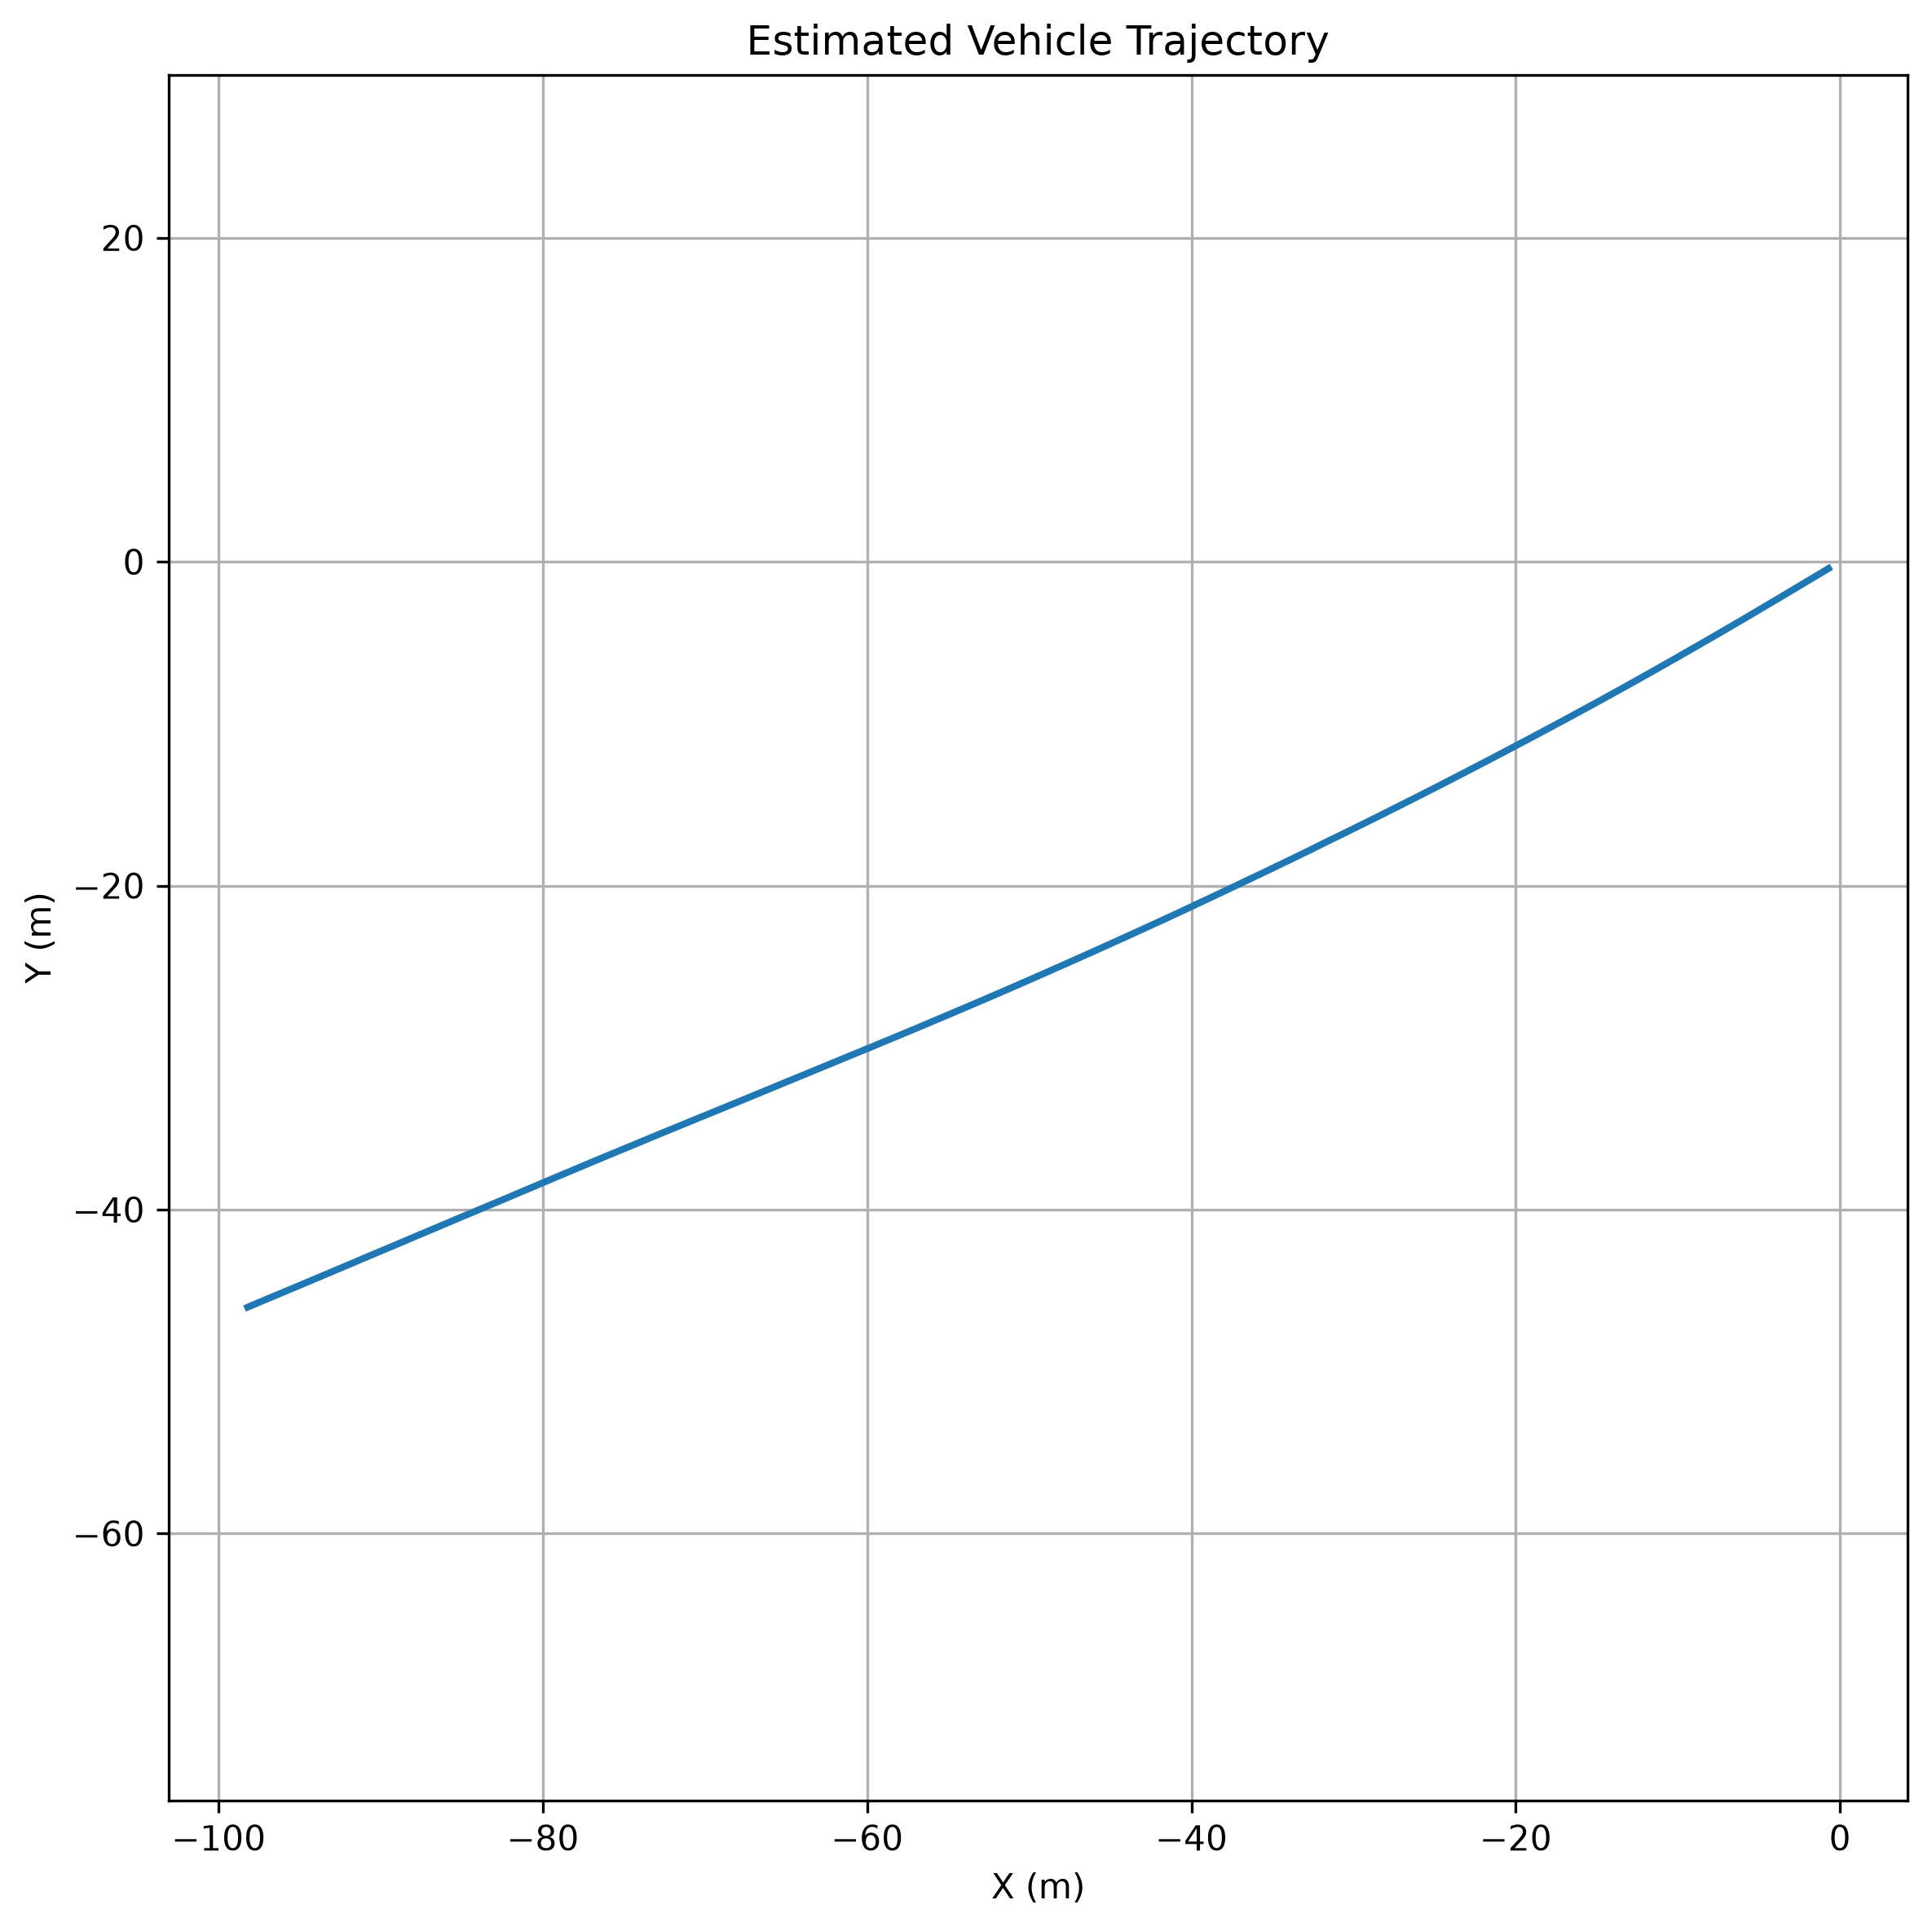

In [20]:
# ============================================================
# Cell 20
# Estimated Vehicle Trajectory
# ============================================================

plt.figure(figsize=(8,8))

plt.plot(
    ekf["Estimated X"],
    ekf["Estimated Y"],
    linewidth=2
)

plt.xlabel("X (m)")
plt.ylabel("Y (m)")

plt.title("Estimated Vehicle Trajectory")

plt.axis("equal")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Figure_13_Trajectory.png",
    dpi=300
)

plt.show()

In [21]:
# ============================================================
# Cell 21
# Regression Performance
# ============================================================

rmse = np.sqrt(mean_squared_error(
    ml["Actual Position Error"],
    ml["Predicted Position Error"]
))

mae = mean_absolute_error(
    ml["Actual Position Error"],
    ml["Predicted Position Error"]
)

r2 = r2_score(
    ml["Actual Position Error"],
    ml["Predicted Position Error"]
)

metrics = pd.DataFrame({
    "Metric":["RMSE","MAE","R2"],
    "Value":[rmse,mae,r2]
})

display(metrics)

metrics.to_csv(
    TABLE_DIR/"ML_Regression_Metrics.csv",
    index=False
)

,Metric,Value
0,RMSE,0.037710
1,MAE,0.029402
2,R2,0.983307


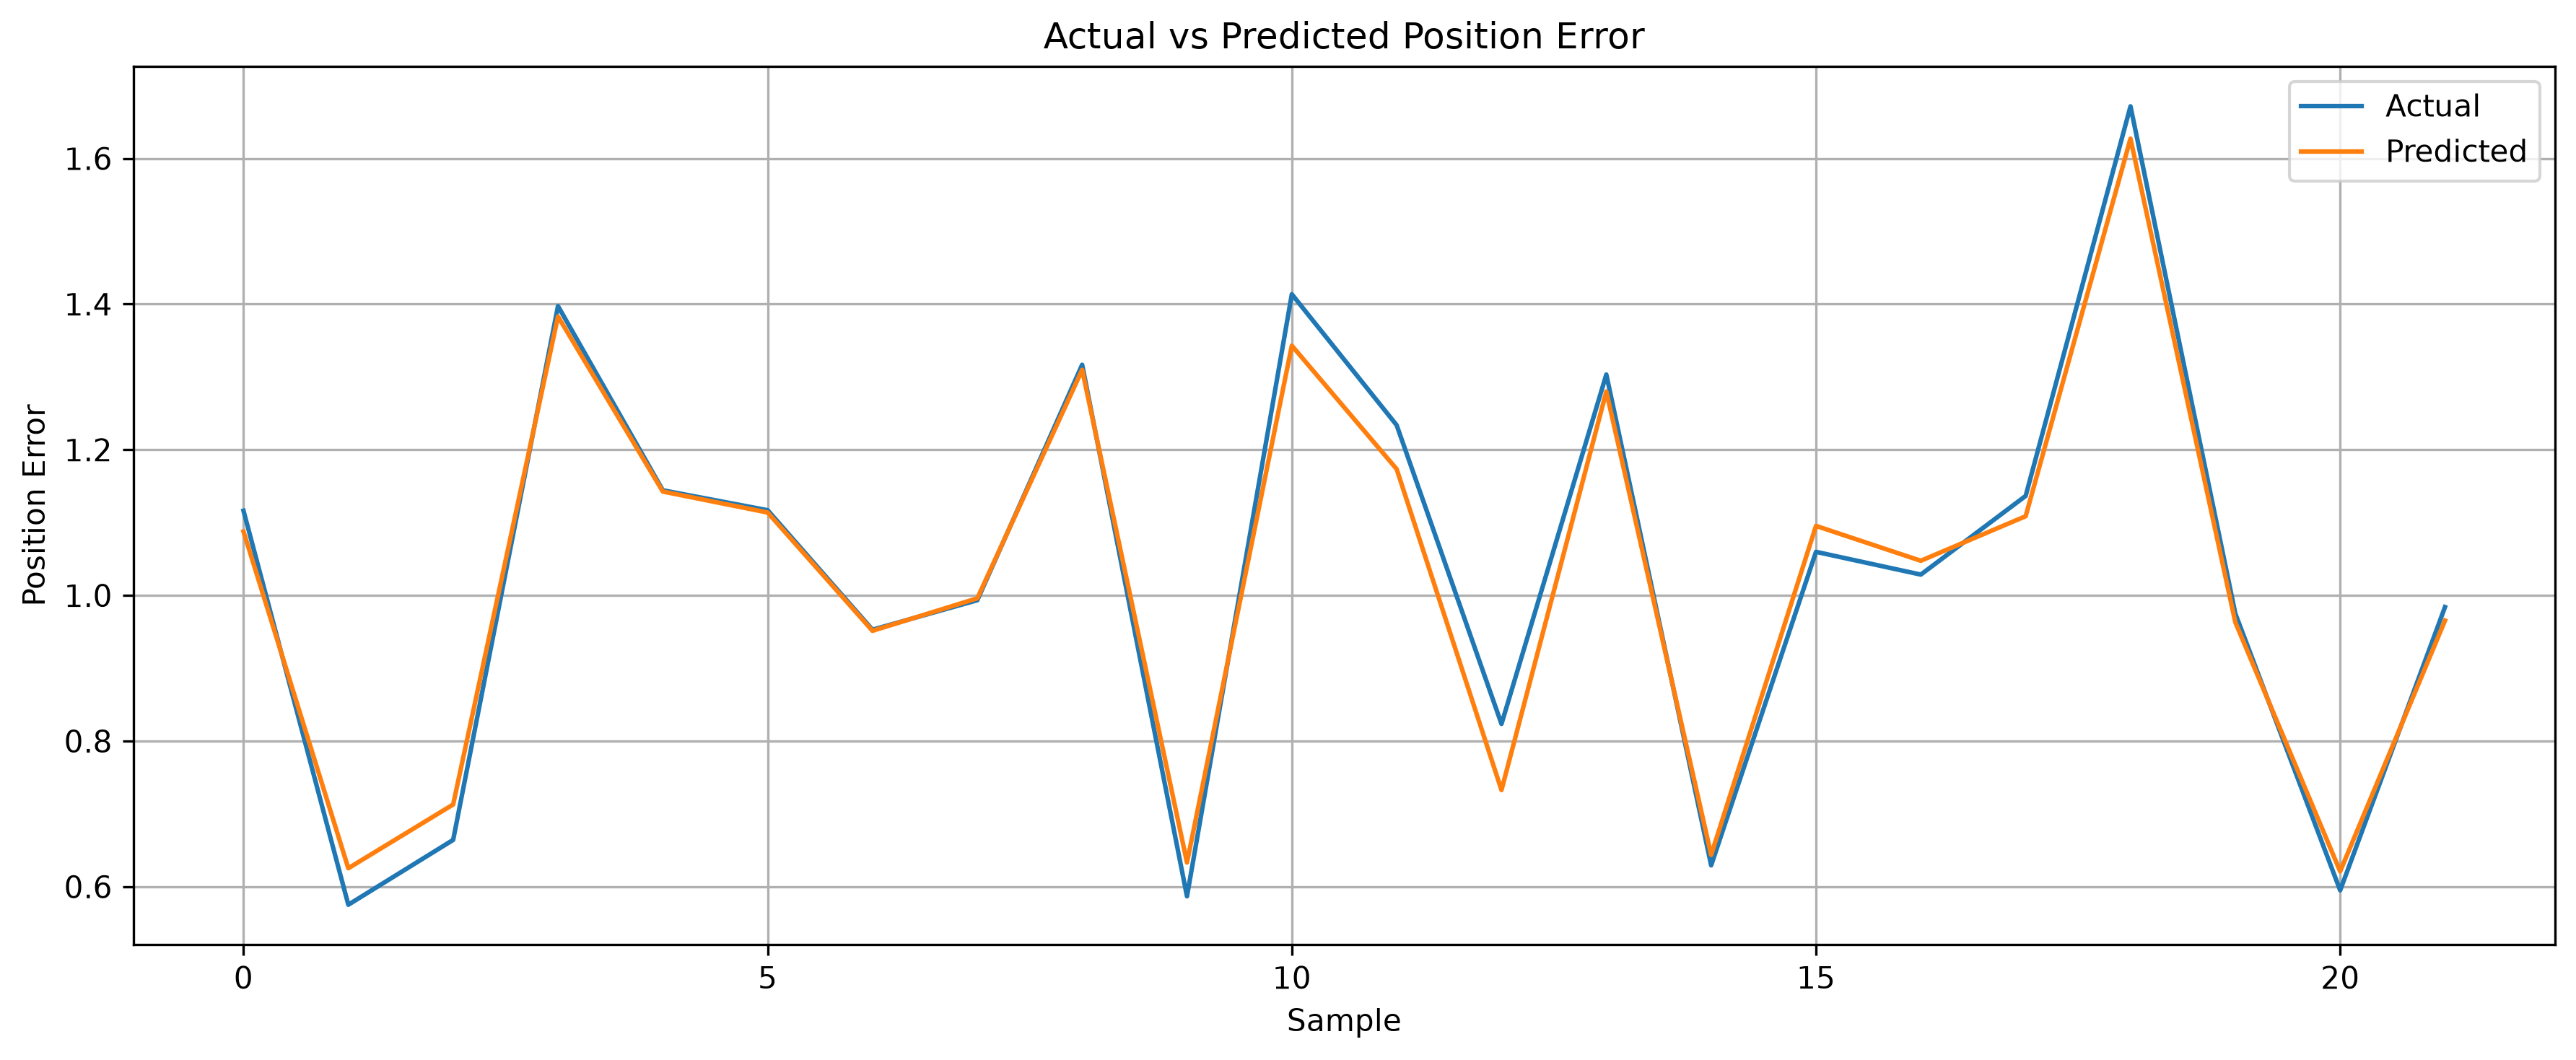

In [22]:
# ============================================================
# Cell 22
# Actual vs Predicted Position Error
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(
    ml["Actual Position Error"],
    label="Actual"
)

plt.plot(
    ml["Predicted Position Error"],
    label="Predicted"
)

plt.xlabel("Sample")
plt.ylabel("Position Error")

plt.title("Actual vs Predicted Position Error")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR/"Figure_14_Actual_vs_Predicted.png",
    dpi=300
)

plt.show()

In [23]:
# ============================================================
# Cell 24
# Performance Metrics
# ============================================================

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

rmse = np.sqrt(
    mean_squared_error(
        ml["Actual Position Error"],
        ml["Predicted Position Error"]
    )
)

mae = mean_absolute_error(
    ml["Actual Position Error"],
    ml["Predicted Position Error"]
)

r2 = r2_score(
    ml["Actual Position Error"],
    ml["Predicted Position Error"]
)

performance = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R²"],
    "Value": [rmse, mae, r2]
})

display(performance)

performance.to_csv(
    TABLE_DIR / "performance_metrics.csv",
    index=False
)

print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R²   : {r2:.4f}")

,Metric,Value
0,RMSE,0.037710
1,MAE,0.029402
2,R²,0.983307


RMSE : 0.0377
MAE  : 0.0294
R²   : 0.9833


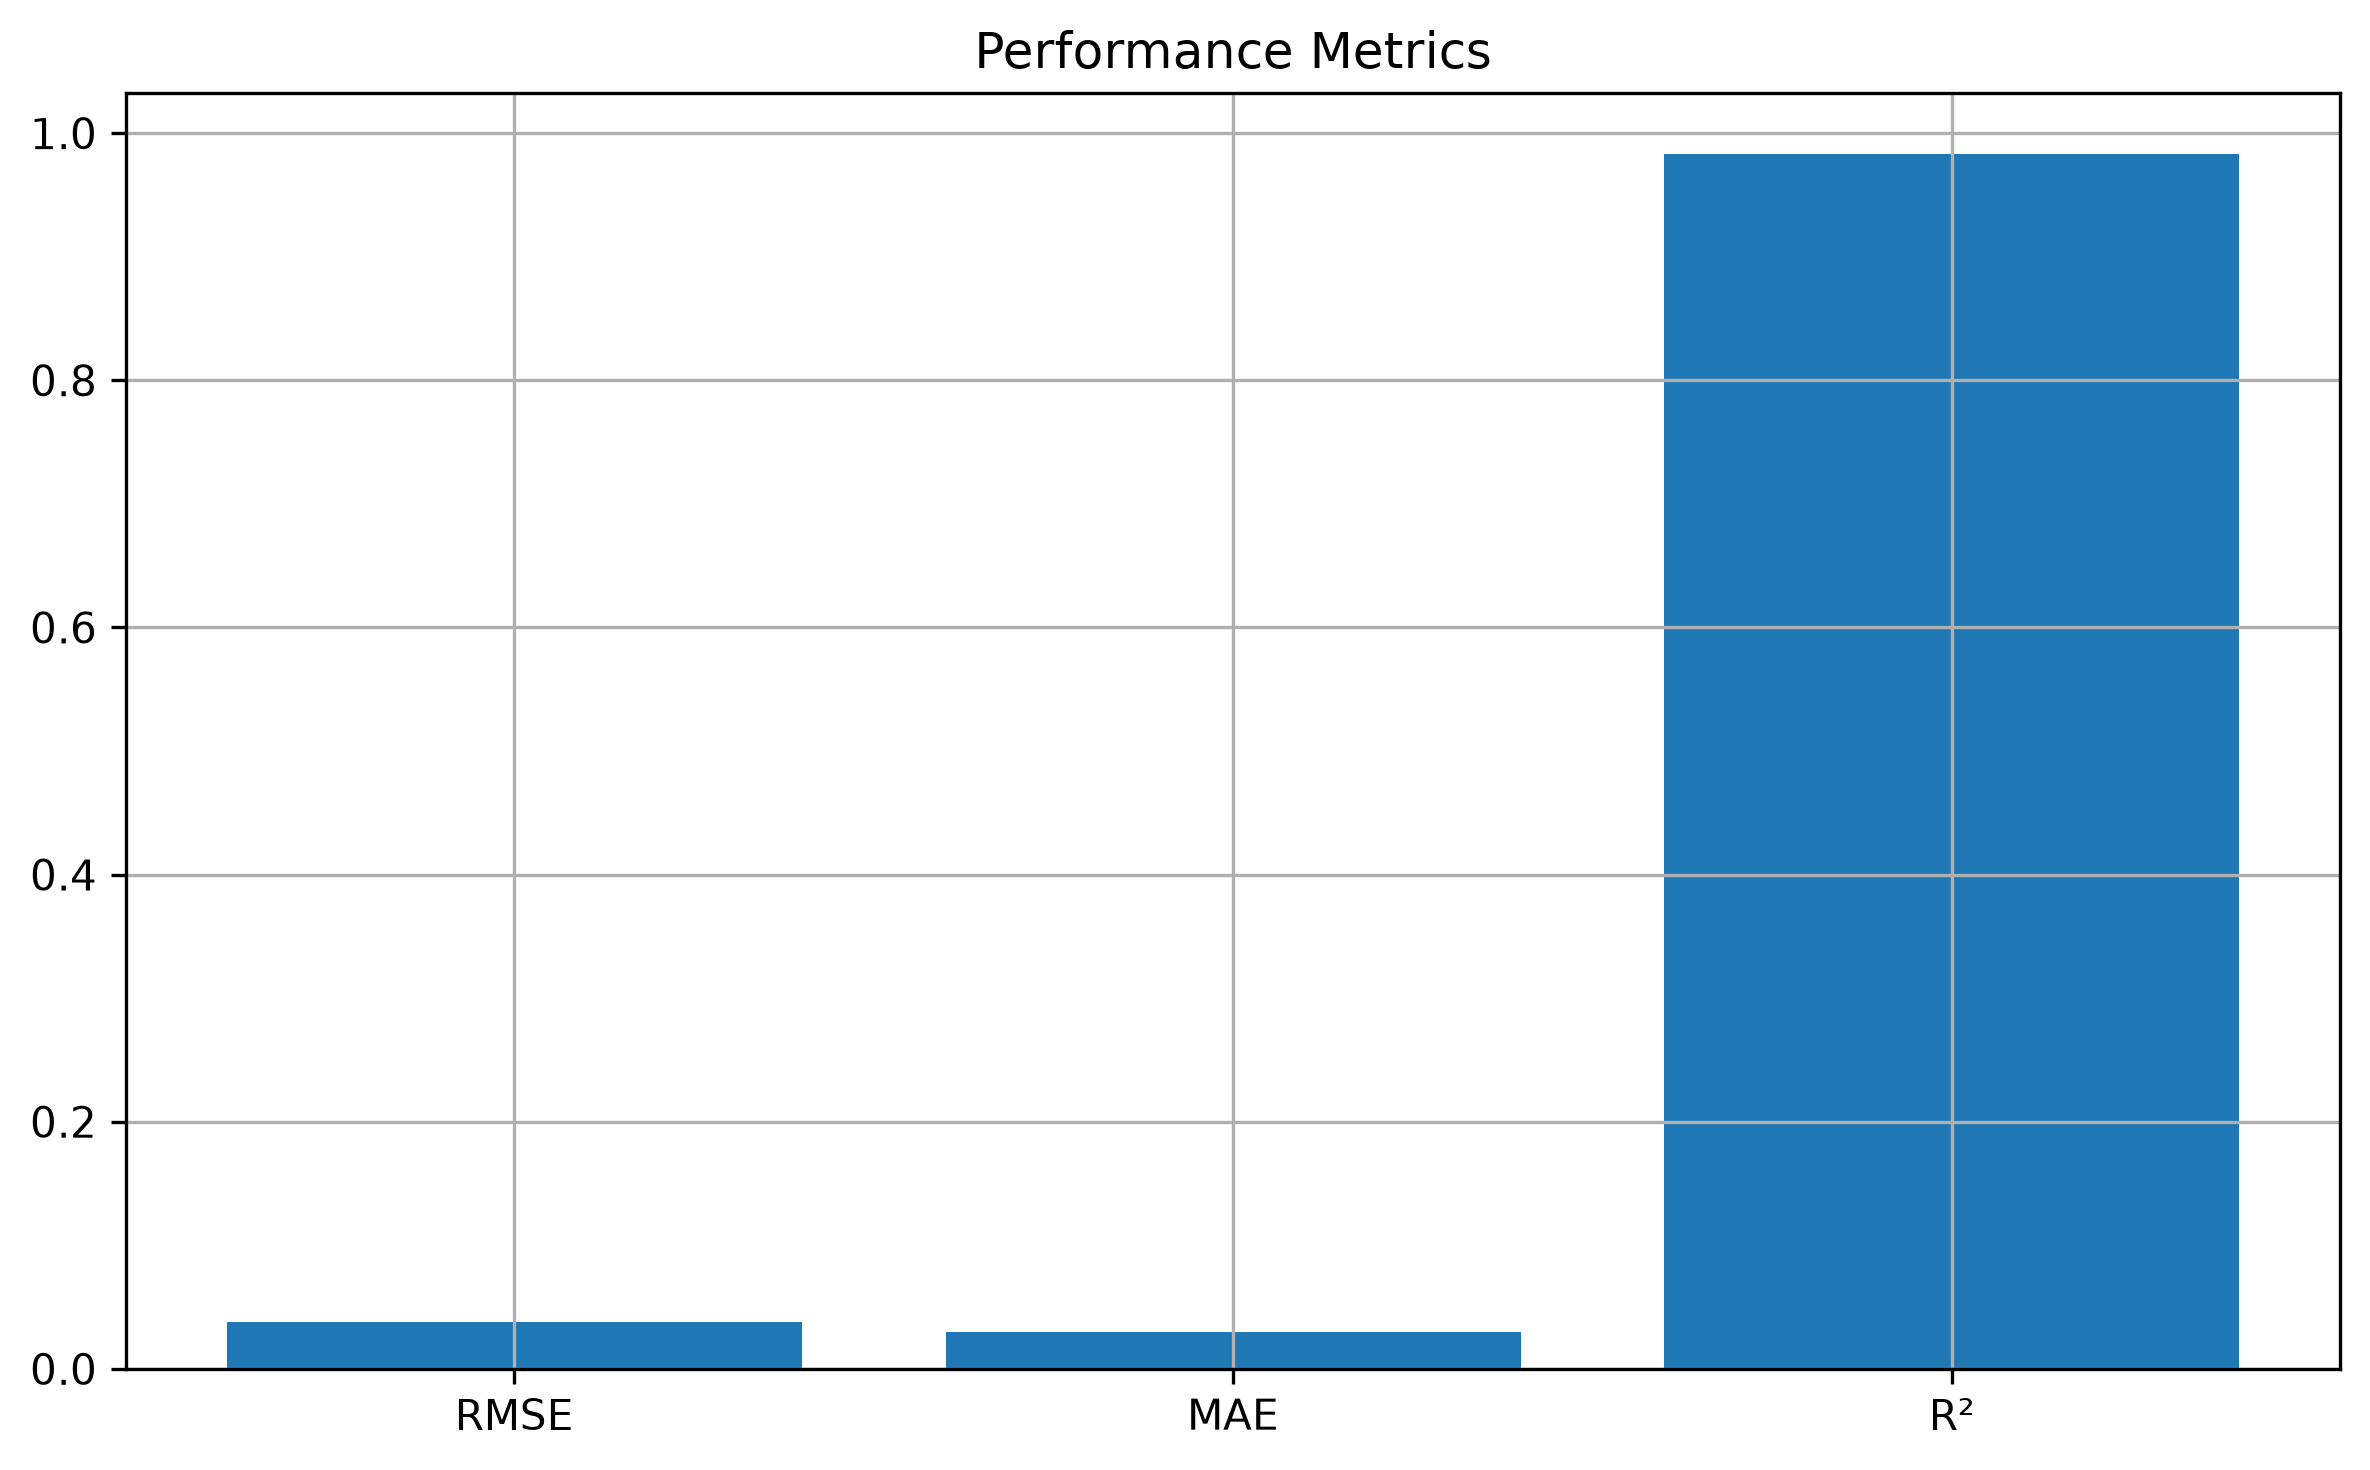

In [24]:
# ============================================================
# Cell 25
# Performance Comparison
# ============================================================

plt.figure(figsize=(8,5))

plt.bar(
    performance["Metric"],
    performance["Value"]
)

plt.title("Performance Metrics")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure_16_Performance_Comparison.png",
    dpi=300
)

plt.show()

In [25]:
# ============================================================
# Cell 26
# Overall Results Summary
# ============================================================

summary = pd.DataFrame({

"Stage":[

"Dataset Validation",

"Sensor Quality",

"Sensor Confidence",

"Adaptive Weights",

"Sensor Fusion",

"Adaptive EKF",

"Random Forest"

],

"Status":[

"Completed",

"Completed",

"Completed",

"Completed",

"Completed",

"Completed",

"Completed"

]

})

display(summary)

summary.to_csv(

TABLE_DIR /

"overall_pipeline_summary.csv",

index=False

)

,Stage,Status
0,Dataset Validation,Completed
1,Sensor Quality,Completed
2,Sensor Confidence,Completed
3,Adaptive Weights,Completed
4,Sensor Fusion,Completed
5,Adaptive EKF,Completed
6,Random Forest,Completed


In [26]:
# ============================================================
# Cell 27
# Export Results to Excel
# ============================================================

import pandas as pd

excel_file = TABLE_DIR / "Paper2_Results.xlsx"

try:
    import openpyxl

    with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

        # -----------------------------
        # Performance Metrics
        # -----------------------------
        if 'performance' in globals():
            performance.to_excel(
                writer,
                sheet_name="Performance",
                index=False
            )

        # -----------------------------
        # Pipeline Summary
        # -----------------------------
        if 'summary' in globals():
            summary.to_excel(
                writer,
                sheet_name="Pipeline Summary",
                index=False
            )

        # -----------------------------
        # Camera Statistics
        # -----------------------------
        if 'camera_stats' in globals():
            camera_stats.to_excel(
                writer,
                sheet_name="Camera Stats"
            )

        # -----------------------------
        # SCI Statistics
        # -----------------------------
        if 'corr' in globals():
            corr.to_excel(
                writer,
                sheet_name="SCI Correlation"
            )

        # -----------------------------
        # Weight Statistics
        # -----------------------------
        if 'weight_stats' in globals():
            weight_stats.to_excel(
                writer,
                sheet_name="Adaptive Weights"
            )

        # -----------------------------
        # Fusion Statistics
        # -----------------------------
        if 'fusion_stats' in globals():
            fusion_stats.to_excel(
                writer,
                sheet_name="Fusion Statistics"
            )

        # -----------------------------
        # EKF Statistics
        # -----------------------------
        if 'ekf_stats' in globals():
            ekf_stats.to_excel(
                writer,
                sheet_name="EKF Statistics"
            )

        # -----------------------------
        # Dataset Summary
        # -----------------------------
        if 'dataset_summary' in globals():
            dataset_summary.to_excel(
                writer,
                sheet_name="Dataset Summary",
                index=False
            )

        # -----------------------------
        # Dataset Statistics
        # -----------------------------
        if 'dataset_stats' in globals():
            dataset_stats.to_excel(
                writer,
                sheet_name="Dataset Statistics",
                index=False
            )

        # -----------------------------
        # SCI Raw Data
        # -----------------------------
        if 'sci' in globals():
            sci.to_excel(
                writer,
                sheet_name="SCI Data",
                index=False
            )

        # -----------------------------
        # Adaptive Weights
        # -----------------------------
        if 'weights' in globals():
            weights.to_excel(
                writer,
                sheet_name="Weights",
                index=False
            )

        # -----------------------------
        # Sensor Fusion
        # -----------------------------
        if 'fusion' in globals():
            fusion.to_excel(
                writer,
                sheet_name="Fusion",
                index=False
            )

        # -----------------------------
        # EKF
        # -----------------------------
        if 'ekf' in globals():
            ekf.to_excel(
                writer,
                sheet_name="Adaptive EKF",
                index=False
            )

        # -----------------------------
        # Machine Learning
        # -----------------------------
        if 'ml' in globals():
            ml.to_excel(
                writer,
                sheet_name="ML Results",
                index=False
            )

    print("="*60)
    print("Excel workbook successfully created.")
    print(excel_file)
    print("="*60)

except ModuleNotFoundError:

    print("="*60)
    print("openpyxl is NOT installed.")
    print("Excel export skipped.")
    print()
    print("Install using:")
    print("    pip install openpyxl")
    print("or")
    print("    %pip install openpyxl")
    print("="*60)

except Exception as e:

    print("="*60)
    print("Error while exporting Excel:")
    print(e)
    print("="*60)

Excel workbook successfully created.
D:\Research\Papers\Paper_2\tables\Paper2_Results.xlsx


In [27]:
# ============================================================
# Cell 28
# Generated Figures
# ============================================================

print("="*80)
print("GENERATED FIGURES")
print("="*80)

for file in sorted(FIGURE_DIR.glob("*.png")):
    print(file.name)

GENERATED FIGURES
absolute_camera_weight_change.png
adaptive_sensor_weights.png
adaptive_sensor_weights_2011_09_26_drive_0001_sync.png
adaptive_sensor_weights_2011_09_26_drive_0002_sync.png
adaptive_sensor_weights_2011_09_26_drive_0005_sync.png
adaptive_sensor_weights_2011_09_26_drive_0009_sync.png
adaptive_sensor_weights_2011_09_26_drive_0011_sync.png
adaptive_sensor_weights_2011_09_26_drive_0015_sync.png
adaptive_sensor_weights_2011_09_26_drive_0018_sync.png
adaptive_sensor_weights_2011_09_26_drive_0020_sync.png
adaptive_sensor_weights_2011_09_26_drive_0022_sync.png
adaptive_weight_distribution.png
adaptive_weight_distribution_2011_09_26_drive_0001_sync.png
adaptive_weight_distribution_2011_09_26_drive_0002_sync.png
adaptive_weight_distribution_2011_09_26_drive_0005_sync.png
adaptive_weight_distribution_2011_09_26_drive_0009_sync.png
adaptive_weight_distribution_2011_09_26_drive_0011_sync.png
adaptive_weight_distribution_2011_09_26_drive_0015_sync.png
adaptive_weight_distribution_201

In [28]:
# ============================================================
# Cell 29
# Generated Tables
# ============================================================

print("="*80)
print("GENERATED TABLES")
print("="*80)

for file in sorted(TABLE_DIR.glob("*")):
    print(file.name)

GENERATED TABLES
adaptive_ekf_statistics.csv
adaptive_weight_statistics.csv
camera_confidence_statistics.csv
dataset_statistics.csv
dataset_summary.csv
fusion_statistics.csv
localization_level_distribution.csv
ML_Regression_Metrics.csv
overall_pipeline_summary.csv
Paper2_Results.xlsx
performance_metrics.csv
SCI_Correlation.csv


In [29]:
# ============================================================
# Cell 30
# Final Summary
# ============================================================

print("="*90)
print("CONFIDENCE-DRIVEN ADAPTIVE MULTI-SENSOR FUSION FRAMEWORK")
print("="*90)

print("""
Pipeline Executed Successfully

✓ Dataset Validation
✓ Sensor Quality Assessment
✓ Camera Confidence Estimation
✓ GPS Confidence Estimation
✓ IMU Confidence Estimation
✓ Sensor Confidence Index (SCI)
✓ Adaptive Sensor Weight Estimation
✓ Confidence-Driven Sensor Fusion
✓ Confidence-Driven Adaptive EKF
✓ Random Forest Localization Reliability Prediction
✓ Performance Evaluation
✓ Publication Figures Generated
✓ Publication Tables Generated
""")

print("="*90)

print(f"Figures Folder : {FIGURE_DIR}")
print(f"Tables Folder  : {TABLE_DIR}")

print("="*90)
print("Notebook Completed Successfully")
print("="*90)

CONFIDENCE-DRIVEN ADAPTIVE MULTI-SENSOR FUSION FRAMEWORK

Pipeline Executed Successfully

✓ Dataset Validation
✓ Sensor Quality Assessment
✓ Camera Confidence Estimation
✓ GPS Confidence Estimation
✓ IMU Confidence Estimation
✓ Sensor Confidence Index (SCI)
✓ Adaptive Sensor Weight Estimation
✓ Confidence-Driven Sensor Fusion
✓ Confidence-Driven Adaptive EKF
✓ Random Forest Localization Reliability Prediction
✓ Performance Evaluation
✓ Publication Figures Generated
✓ Publication Tables Generated

Figures Folder : D:\Research\Papers\Paper_2\figures
Tables Folder  : D:\Research\Papers\Paper_2\tables
Notebook Completed Successfully
